# LLM Apology Behaviour in Repeated Prisoner's Dilemma Games

**Research Question:** How do large language models decide whether and how to apologise after fixed outcomes in a controlled Prisoner's Dilemma, and how does access to prior-round history affect these decisions?

**Experimental Design:**
- 4 LLMs: GPT-5.5, Claude Opus 4.8, Llama 4 Scout, Mistral Large 3
- 2 history conditions: No Memory vs. Memory-1
- 10 runs per model × history condition
- 4 fixed outcomes per game in order: R → S → T → P
- 2 agents per game, 4 rounds each
- Numerical values are **penalties** (lower = better)
- Game actions/outcomes are fixed; LLMs only decide whether to apologise

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from ast import literal_eval
import re
import os
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.figsize': (8, 5),
    'axes.spines.top': False,
    'axes.spines.right': False,
})

FIGURES_DIR = 'figures'
TABLES_DIR = 'tables'
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

MODEL_NAMES = {
    'OR_GPT5.5': 'GPT-5.5',
    'OR_Claude48': 'Claude Opus 4.8',
    'OR_Llama4Scout': 'Llama 4 Scout',
    'OR_MistralLarge3': 'Mistral Large 3',
}
MODEL_ORDER = ['GPT-5.5', 'Claude Opus 4.8', 'Llama 4 Scout', 'Mistral Large 3']
OUTCOME_ORDER = ['R', 'S', 'T', 'P']
HISTORY_ORDER = ['No Memory', 'Memory-1']

MODEL_PALETTE = {
    'GPT-5.5': '#4C72B0',
    'Claude Opus 4.8': '#DD8452',
    'Llama 4 Scout': '#55A868',
    'Mistral Large 3': '#C44E52',
}

print('Imports complete.')

Imports complete.


## 1. Data Loading and Validation

In [2]:
raw = pd.read_csv('resources/results/combined_results.csv')
print(f'Raw dataset: {raw.shape[0]} game-level rows, {raw.shape[1]} columns')
print(f'Columns: {list(raw.columns)}')

Raw dataset: 80 game-level rows, 30 columns
Columns: ['game_id', 'language', 'experiment_mode', 'n_rounds_is_known', 'max_rounds', 'played_rounds', 'agents_communicate', 'agent1_name', 'agent1_llm', 'agent1_personality', 'agent1_knows_opponent_with_prob', 'agent1_strategies', 'agent1_scores', 'agent1_messages', 'agent1_apology_decisions', 'agent1_apology_messages', 'agent1_reason_codes', 'agent2_name', 'agent2_llm', 'agent2_personality', 'agent2_knows_opponent_with_prob', 'agent2_strategies', 'agent2_scores', 'agent2_messages', 'agent2_apology_decisions', 'agent2_apology_messages', 'agent2_reason_codes', 'run_number', 'folder_name', 'source_file']


In [3]:
def safe_literal_eval(val):
    if isinstance(val, str):
        try:
            return literal_eval(val)
        except (ValueError, SyntaxError):
            return val
    return val

def determine_history_condition(folder_name):
    fn = str(folder_name).lower()
    if 'memory1' in fn or 'memory_1' in fn:
        return 'Memory-1'
    elif 'nomemory' in fn or 'no_memory' in fn:
        return 'No Memory'
    return 'Unknown'

def determine_model(llm_code):
    return MODEL_NAMES.get(llm_code, llm_code)

OUTCOME_SEQUENCE = ['R', 'S', 'T', 'P']
PENALTY_MAP = {
    'R': {'agent1': 2, 'agent2': 2},
    'S': {'agent1': 10, 'agent2': 0},
    'T': {'agent1': 0, 'agent2': 10},
    'P': {'agent1': 6, 'agent2': 6},
}

rows = []
for _, game_row in raw.iterrows():
    folder = game_row['folder_name']
    run = game_row['run_number']
    history_cond = determine_history_condition(folder)

    for agent_prefix in ['agent1', 'agent2']:
        llm_code = game_row[f'{agent_prefix}_llm']
        model = determine_model(llm_code)

        apology_decisions = safe_literal_eval(game_row[f'{agent_prefix}_apology_decisions'])
        apology_messages = safe_literal_eval(game_row[f'{agent_prefix}_apology_messages'])
        reason_codes = safe_literal_eval(game_row[f'{agent_prefix}_reason_codes'])
        scores = safe_literal_eval(game_row[f'{agent_prefix}_scores'])

        for round_idx in range(4):
            outcome = OUTCOME_SEQUENCE[round_idx]
            own_penalty = scores[round_idx] if isinstance(scores, list) and len(scores) > round_idx else np.nan

            other_agent = 'agent2' if agent_prefix == 'agent1' else 'agent1'
            other_scores = safe_literal_eval(game_row[f'{other_agent}_scores'])
            opponent_penalty = other_scores[round_idx] if isinstance(other_scores, list) and len(other_scores) > round_idx else np.nan

            apology_dec = apology_decisions[round_idx] if isinstance(apology_decisions, list) and len(apology_decisions) > round_idx else ''
            apology_msg = apology_messages[round_idx] if isinstance(apology_messages, list) and len(apology_messages) > round_idx else ''
            reason = reason_codes[round_idx] if isinstance(reason_codes, list) and len(reason_codes) > round_idx else ''

            rows.append({
                'model': model,
                'history_condition': history_cond,
                'run': run,
                'agent': agent_prefix,
                'round': round_idx + 1,
                'outcome': outcome,
                'own_penalty': own_penalty,
                'opponent_penalty': opponent_penalty,
                'apology_decision': apology_dec,
                'reason_code': reason,
                'apology_message': apology_msg if isinstance(apology_msg, str) else str(apology_msg),
            })

df = pd.DataFrame(rows)
df['apologised'] = (df['apology_decision'].str.upper() == 'YES').astype(int)
df['penalty_diff'] = df['own_penalty'] - df['opponent_penalty']
print(f'Observation-level dataframe: {len(df)} rows')
print(f'\nModels: {sorted(df["model"].unique())}')
print(f'History conditions: {sorted(df["history_condition"].unique())}')
print(f'Runs per model x history: {df.groupby(["model", "history_condition"])["run"].nunique().values}')
df.head(8)

Observation-level dataframe: 640 rows

Models: ['Claude Opus 4.8', 'GPT-5.5', 'Llama 4 Scout', 'Mistral Large 3']
History conditions: ['Memory-1', 'No Memory']
Runs per model x history: [10 10 10 10 10 10 10 10]


,model,history_condition,run,agent,round,outcome,own_penalty,opponent_penalty,apology_decision,reason_code,apology_message,apologised,penalty_diff
0,Claude Opus 4.8,Memory-1,0,agent1,1,R,2,2,NO,no_responsibility,,0,0
1,Claude Opus 4.8,Memory-1,0,agent1,2,S,10,0,YES,strategic_future_benefit,Sorry for the outcome this round. I'd like to ...,1,10
2,Claude Opus 4.8,Memory-1,0,agent1,3,T,0,10,NO,no_responsibility,,0,-10
3,Claude Opus 4.8,Memory-1,0,agent1,4,P,6,6,NO,no_responsibility,,0,0
4,Claude Opus 4.8,Memory-1,0,agent2,1,R,2,2,NO,no_responsibility,,0,0
5,Claude Opus 4.8,Memory-1,0,agent2,2,S,0,10,NO,no_responsibility,,0,-10
6,Claude Opus 4.8,Memory-1,0,agent2,3,T,10,0,YES,repair_trust,Sorry this round went my way. You reached out ...,1,10
7,Claude Opus 4.8,Memory-1,0,agent2,4,P,6,6,NO,no_responsibility,Great outcome this round—we both cooperated an...,0,0


In [4]:
print('=== DATA VALIDATION ===')
print(f'\n1. Total observations: {len(df)}')
expected = 4 * 2 * 10 * 2 * 4  # models * history * runs * agents * rounds
print(f'   Expected: {expected}')
print(f'   Match: {len(df) == expected}')

print(f'\n2. Missing values:')
print(df.isnull().sum())

print(f'\n3. Outcome ordering per game (should be R, S, T, P):')
outcome_seqs = df.groupby(['model', 'history_condition', 'run', 'agent'])['outcome'].apply(list)
unique_seqs = set(tuple(s) for s in outcome_seqs)
print(f'   Unique outcome sequences: {unique_seqs}')

print(f'\n4. Penalty verification from config (OptionA=Defect, OptionB=Cooperate):')
print('   R (Mutual Cooperation): both OptionB → penalty 2 each')
print('   S (Sucker): agent1 OptionB (cooperate), agent2 OptionA (defect) → agent1=10, agent2=0')
print('   T (Temptation): agent1 OptionA (defect), agent2 OptionB (cooperate) → agent1=0, agent2=10')
print('   P (Mutual Defection): both OptionA → penalty 6 each')
penalty_check = df.groupby(['outcome', 'agent'])[['own_penalty']].agg(['mean', 'std', 'min', 'max'])
print(penalty_check)

print(f'\n5. Apology decision values: {df["apology_decision"].value_counts().to_dict()}')
print(f'\n6. Reason code values: {df["reason_code"].value_counts().to_dict()}')

print(f'\n7. Duplicate check:')
dupes = df.duplicated(subset=['model', 'history_condition', 'run', 'agent', 'round']).sum()
print(f'   Duplicate rows: {dupes}')

print(f'\n8. Unexpected apology decision values: {set(df["apology_decision"].unique()) - {"YES", "NO"}}')

=== DATA VALIDATION ===

1. Total observations: 640
   Expected: 640
   Match: True

2. Missing values:
model                0
history_condition    0
run                  0
agent                0
round                0
outcome              0
own_penalty          0
opponent_penalty     0
apology_decision     0
reason_code          0
apology_message      0
apologised           0
penalty_diff         0
dtype: int64

3. Outcome ordering per game (should be R, S, T, P):
   Unique outcome sequences: {('R', 'S', 'T', 'P')}

4. Penalty verification from config (OptionA=Defect, OptionB=Cooperate):
   R (Mutual Cooperation): both OptionB → penalty 2 each
   S (Sucker): agent1 OptionB (cooperate), agent2 OptionA (defect) → agent1=10, agent2=0
   T (Temptation): agent1 OptionA (defect), agent2 OptionB (cooperate) → agent1=0, agent2=10
   P (Mutual Defection): both OptionA → penalty 6 each
               own_penalty             
                      mean  std min max
outcome agent                 

### Penalty Structure Verification

From the game configuration, the payoff matrix uses **penalties** (lower is better). OptionA = Defect, OptionB = Cooperate (these labels were not shown to agents):

| Outcome | Round | Agent 1 Action | Agent 2 Action | Agent 1 Penalty | Agent 2 Penalty | Interpretation |
|---------|-------|---------------|----------------|-----------------|-----------------|----------------|
| **R** (Reward / Mutual Cooperation) | 1 | OptionB (Cooperate) | OptionB (Cooperate) | 2 | 2 | Low mutual penalty |
| **S** (Sucker's Payoff) | 2 | OptionB (Cooperate) | OptionA (Defect) | 10 | 0 | Agent1 cooperated but exploited; agent2 defected, best outcome |
| **T** (Temptation to Defect) | 3 | OptionA (Defect) | OptionB (Cooperate) | 0 | 10 | Agent1 defected, best outcome; agent2 cooperated but exploited |
| **P** (Punishment / Mutual Defection) | 4 | OptionA (Defect) | OptionA (Defect) | 6 | 6 | Moderate mutual penalty |

**Critical note:** In this penalty framing, mutual cooperation (R=2) yields a *lower* penalty than mutual defection (P=6), consistent with standard PD incentives. The penalty ordering is T(0) < R(2) < P(6) < S(10). The outcome sequence R→S→T→P is fixed, so outcome and round are fully confounded.

## 2. Descriptive Statistics and Apology Rates

In [5]:
def compute_apology_rate(group, ci=0.95):
    """Compute apology rate with Wilson score confidence interval."""
    n = len(group)
    if n == 0:
        return pd.Series({'rate': np.nan, 'ci_lower': np.nan, 'ci_upper': np.nan, 'n': 0})
    k = group.sum()
    p_hat = k / n
    z = stats.norm.ppf(1 - (1 - ci) / 2)
    denom = 1 + z**2 / n
    centre = (p_hat + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * n)) / n) / denom
    return pd.Series({
        'rate': p_hat,
        'ci_lower': max(0, centre - margin),
        'ci_upper': min(1, centre + margin),
        'n': n,
        'n_apologies': int(k)
    })

print('Rate computation functions defined.')

Rate computation functions defined.


In [6]:
rates_outcome = df.groupby('outcome')['apologised'].apply(compute_apology_rate).unstack()
rates_outcome = rates_outcome.reindex(OUTCOME_ORDER)
print('Apology rates by outcome (R/S/T/P):')
rates_outcome[['rate', 'ci_lower', 'ci_upper', 'n', 'n_apologies']]

Apology rates by outcome (R/S/T/P):


,rate,ci_lower,ci_upper,n,n_apologies
outcome,,,,,
R,0.21875,0.161701,0.288987,160.0,35.0
S,0.55000,0.472642,0.625014,160.0,88.0
T,0.51875,0.441802,0.594819,160.0,83.0
P,0.20000,0.145383,0.268685,160.0,32.0


In [7]:
rates_model = df.groupby('model')['apologised'].apply(compute_apology_rate).unstack()
rates_model = rates_model.reindex(MODEL_ORDER)
print('Apology rates by model:')
rates_model[['rate', 'ci_lower', 'ci_upper', 'n', 'n_apologies']]

Apology rates by model:


,rate,ci_lower,ci_upper,n,n_apologies
model,,,,,
GPT-5.5,0.48125,0.405181,0.558198,160.0,77.0
Claude Opus 4.8,0.20625,0.150801,0.275474,160.0,33.0
Llama 4 Scout,0.22500,0.167183,0.295713,160.0,36.0
Mistral Large 3,0.57500,0.497527,0.648957,160.0,92.0


In [8]:
rates_history = df.groupby('history_condition')['apologised'].apply(compute_apology_rate).unstack()
rates_history = rates_history.reindex(HISTORY_ORDER)
print('Apology rates by history condition:')
rates_history[['rate', 'ci_lower', 'ci_upper', 'n', 'n_apologies']]

Apology rates by history condition:


,rate,ci_lower,ci_upper,n,n_apologies
history_condition,,,,,
No Memory,0.396875,0.344798,0.451398,320.0,127.0
Memory-1,0.346875,0.296819,0.400563,320.0,111.0


In [9]:
rates_mh = df.groupby(['model', 'history_condition'])['apologised'].apply(compute_apology_rate).unstack()
rates_mh = rates_mh.reindex(pd.MultiIndex.from_product([MODEL_ORDER, HISTORY_ORDER]))
print('Apology rates by model x history:')
rates_mh[['rate', 'ci_lower', 'ci_upper', 'n', 'n_apologies']]

Apology rates by model x history:


rate  ci_lower  ci_upper     n  n_apologies
GPT-5.5         No Memory  0.4625  0.357480  0.570956  80.0         37.0
                Memory-1   0.5000  0.392974  0.607026  80.0         40.0
Claude Opus 4.8 No Memory  0.2500  0.168062  0.354847  80.0         20.0
                Memory-1   0.1625  0.097498  0.258429  80.0         13.0
Llama 4 Scout   No Memory  0.3750  0.276942  0.484513  80.0         30.0
                Memory-1   0.0750  0.034825  0.154120  80.0          6.0
Mistral Large 3 No Memory  0.5000  0.392974  0.607026  80.0         40.0
                Memory-1   0.6500  0.540800  0.745454  80.0         52.0

In [10]:
rates_mho = df.groupby(['model', 'history_condition', 'outcome'])['apologised'].apply(compute_apology_rate).unstack()
idx = pd.MultiIndex.from_product([MODEL_ORDER, HISTORY_ORDER, OUTCOME_ORDER])
rates_mho = rates_mho.reindex(idx)
print('Apology rates by model x history x outcome:')
rates_mho[['rate', 'ci_lower', 'ci_upper', 'n', 'n_apologies']]

Apology rates by model x history x outcome:


rate  ci_lower  ci_upper     n  n_apologies
GPT-5.5         No Memory R  0.85  0.639581  0.947631  20.0         17.0
                          S  0.50  0.299298  0.700702  20.0         10.0
                          T  0.50  0.299298  0.700702  20.0         10.0
                          P  0.00  0.000000  0.161125  20.0          0.0
                Memory-1  R  0.85  0.639581  0.947631  20.0         17.0
                          S  0.50  0.299298  0.700702  20.0         10.0
                          T  0.55  0.342085  0.741802  20.0         11.0
                          P  0.10  0.027866  0.301034  20.0          2.0
Claude Opus 4.8 No Memory R  0.00  0.000000  0.161125  20.0          0.0
                          S  0.50  0.299298  0.700702  20.0         10.0
                          T  0.50  0.299298  0.700702  20.0         10.0
                          P  0.00  0.000000  0.161125  20.0          0.0
                Memory-1  R  0.00  0.000000  0.161125  20.0          0.0
                          S  0.30  0.145477  0.518973  20.0          6.0
                          T  0.30  0.145477  0.518973  20.0          6.0
                          P  0.05  0.008881  0.236131  20.0          1.0
Llama 4 Scout   No Memory R  0.00  0.000000  0.161125  20.0          0.0
                          S  0.55  0.342085  0.741802  20.0         11.0
                          T  0.60  0.386582  0.781193  20.0         12.0
                          P  0.35  0.181192  0.567146  20.0          7.0
                Memory-1  R  0.05  0.008881  0.236131  20.0          1.0
                          S  0.05  0.008881  0.236131  20.0          1.0
                          T  0.10  0.027866  0.301034  20.0          2.0
                          P  0.10  0.027866  0.301034  20.0          2.0
Mistral Large 3 No Memory R  0.00  0.000000  0.161125  20.0          0.0
                          S  1.00  0.838875  1.000000  20.0         20.0
                          T  1.00  0.838875  1.000000  20.0         20.0
                          P  0.00  0.000000  0.161125  20.0          0.0
                Memory-1  R  0.00  0.000000  0.161125  20.0          0.0
                          S  1.00  0.838875  1.000000  20.0         20.0
                          T  0.60  0.386582  0.781193  20.0         12.0
                          P  1.00  0.838875  1.000000  20.0         20.0

In [11]:
def format_rate_ci(row):
    return f"{row['rate']:.2%} [{row['ci_lower']:.2%}, {row['ci_upper']:.2%}]"

summary_rows = []
for model in MODEL_ORDER:
    for hist in HISTORY_ORDER:
        mask = (df['model'] == model) & (df['history_condition'] == hist)
        row_data = {'Model': model, 'History': hist}
        for outcome in OUTCOME_ORDER:
            omask = mask & (df['outcome'] == outcome)
            sub = df.loc[omask, 'apologised']
            r = compute_apology_rate(sub)
            row_data[outcome] = f"{r['rate']:.1%}"
        overall = compute_apology_rate(df.loc[mask, 'apologised'])
        row_data['Overall'] = f"{overall['rate']:.1%}"
        row_data['N'] = int(overall['n'])
        summary_rows.append(row_data)

summary_table = pd.DataFrame(summary_rows)
print('Table 1: Apology rates by model, history condition, and outcome')
summary_table.to_csv(f'{TABLES_DIR}/table1_apology_rates.csv', index=False)
summary_table

Table 1: Apology rates by model, history condition, and outcome


,Model,History,R,S,T,P,Overall,N
0,GPT-5.5,No Memory,85.0%,50.0%,50.0%,0.0%,46.2%,80
1,GPT-5.5,Memory-1,85.0%,50.0%,55.0%,10.0%,50.0%,80
2,Claude Opus 4.8,No Memory,0.0%,50.0%,50.0%,0.0%,25.0%,80
3,Claude Opus 4.8,Memory-1,0.0%,30.0%,30.0%,5.0%,16.2%,80
4,Llama 4 Scout,No Memory,0.0%,55.0%,60.0%,35.0%,37.5%,80
5,Llama 4 Scout,Memory-1,5.0%,5.0%,10.0%,10.0%,7.5%,80
6,Mistral Large 3,No Memory,0.0%,100.0%,100.0%,0.0%,50.0%,80
7,Mistral Large 3,Memory-1,0.0%,100.0%,60.0%,100.0%,65.0%,80


## 3. Statistical Analysis

### Statistical Approach

Observations within a run are not independent: the same LLM instance generates all 8 decisions (2 agents × 4 rounds) within a single game. We therefore use **run-level aggregation** and **non-parametric permutation/bootstrap methods** as our primary analyses to respect this structure. Where appropriate, we also fit mixed-effects logistic regression with run as a random effect.

We use the following hierarchy:
1. **Run-level apology rates** as the unit of analysis for between-condition comparisons
2. **Permutation tests** for pairwise model and history comparisons
3. **Bootstrap confidence intervals** for uncertainty quantification
4. **Mixed-effects logistic regression** for the full factorial model
5. **Cochran's Q test** for within-run consistency across the 10 runs

In [12]:
run_rates = df.groupby(['model', 'history_condition', 'run'])['apologised'].mean().reset_index()
run_rates.columns = ['model', 'history_condition', 'run', 'apology_rate']
print('Run-level apology rates (each run has 2 agents x 4 rounds = 8 observations):')
print(f'N run-level observations: {len(run_rates)}')
run_rates.groupby(['model', 'history_condition'])['apology_rate'].describe().round(3)

Run-level apology rates (each run has 2 agents x 4 rounds = 8 observations):
N run-level observations: 80


count   mean    std    min    25%    50%  \
model           history_condition                                             
Claude Opus 4.8 Memory-1            10.0  0.162  0.119  0.000  0.031  0.250   
                No Memory           10.0  0.250  0.000  0.250  0.250  0.250   
GPT-5.5         Memory-1            10.0  0.500  0.083  0.375  0.500  0.500   
                No Memory           10.0  0.462  0.060  0.375  0.406  0.500   
Llama 4 Scout   Memory-1            10.0  0.075  0.237  0.000  0.000  0.000   
                No Memory           10.0  0.375  0.167  0.000  0.281  0.438   
Mistral Large 3 Memory-1            10.0  0.650  0.053  0.625  0.625  0.625   
                No Memory           10.0  0.500  0.000  0.500  0.500  0.500   

                                     75%    max  
model           history_condition                
Claude Opus 4.8 Memory-1           0.250  0.250  
                No Memory          0.250  0.250  
GPT-5.5         Memory-1           0.500  0.625  
                No Memory          0.500  0.500  
Llama 4 Scout   Memory-1           0.000  0.750  
                No Memory          0.500  0.500  
Mistral Large 3 Memory-1           0.625  0.750  
                No Memory          0.500  0.500

In [13]:
def permutation_test_two_groups(group_a, group_b, n_perm=10000, seed=42):
    rng = np.random.default_rng(seed)
    obs_diff = group_a.mean() - group_b.mean()
    combined = np.concatenate([group_a, group_b])
    n_a = len(group_a)
    perm_diffs = np.empty(n_perm)
    for i in range(n_perm):
        rng.shuffle(combined)
        perm_diffs[i] = combined[:n_a].mean() - combined[n_a:].mean()
    p_value = (np.abs(perm_diffs) >= np.abs(obs_diff)).mean()
    return obs_diff, p_value

print('=== Memory Effect: Permutation Tests (run-level) ===')
print(f'{"Model":<20} {"No Mem Mean":>12} {"Mem-1 Mean":>12} {"Diff":>10} {"p-value":>10}')
print('-' * 70)
for model in MODEL_ORDER:
    no_mem = run_rates[(run_rates['model'] == model) & (run_rates['history_condition'] == 'No Memory')]['apology_rate'].values
    mem1 = run_rates[(run_rates['model'] == model) & (run_rates['history_condition'] == 'Memory-1')]['apology_rate'].values
    diff, p = permutation_test_two_groups(mem1, no_mem)
    print(f'{model:<20} {no_mem.mean():>12.3f} {mem1.mean():>12.3f} {diff:>+10.3f} {p:>10.4f}')

all_no = run_rates[run_rates['history_condition'] == 'No Memory']['apology_rate'].values
all_mem = run_rates[run_rates['history_condition'] == 'Memory-1']['apology_rate'].values
diff_all, p_all = permutation_test_two_groups(all_mem, all_no)
print(f'{"Overall":<20} {all_no.mean():>12.3f} {all_mem.mean():>12.3f} {diff_all:>+10.3f} {p_all:>10.4f}')

=== Memory Effect: Permutation Tests (run-level) ===
Model                 No Mem Mean   Mem-1 Mean       Diff    p-value
----------------------------------------------------------------------


GPT-5.5                     0.463        0.500     +0.037     0.4526


Claude Opus 4.8             0.250        0.163     -0.087     0.0852


Llama 4 Scout               0.375        0.075     -0.300     0.0082


Mistral Large 3             0.500        0.650     +0.150     0.0000


Overall                     0.397        0.347     -0.050     0.3306


In [14]:
print('=== Model Differences: Kruskal-Wallis Test (run-level) ===')
groups = [run_rates[run_rates['model'] == m]['apology_rate'].values for m in MODEL_ORDER]
H, p_kw = stats.kruskal(*groups)
print(f'H = {H:.3f}, p = {p_kw:.6f}')

print(f'\n=== Pairwise Model Comparisons (permutation tests, run-level) ===')
from itertools import combinations
pairwise_results = []
for m1, m2 in combinations(MODEL_ORDER, 2):
    g1 = run_rates[run_rates['model'] == m1]['apology_rate'].values
    g2 = run_rates[run_rates['model'] == m2]['apology_rate'].values
    diff, p = permutation_test_two_groups(g1, g2)
    pairwise_results.append({'Comparison': f'{m1} vs {m2}', 'Diff': diff, 'p_value': p})

pairwise_df = pd.DataFrame(pairwise_results)
n_tests = len(pairwise_df)
pairwise_df['p_bonferroni'] = np.minimum(pairwise_df['p_value'] * n_tests, 1.0)
pairwise_df['significant'] = pairwise_df['p_bonferroni'] < 0.05
print(pairwise_df.to_string(index=False))

=== Model Differences: Kruskal-Wallis Test (run-level) ===
H = 48.641, p = 0.000000

=== Pairwise Model Comparisons (permutation tests, run-level) ===


                        Comparison     Diff  p_value  p_bonferroni  significant
        GPT-5.5 vs Claude Opus 4.8  0.27500   0.0000        0.0000         True
          GPT-5.5 vs Llama 4 Scout  0.25625   0.0002        0.0012         True
        GPT-5.5 vs Mistral Large 3 -0.09375   0.0010        0.0060         True
  Claude Opus 4.8 vs Llama 4 Scout -0.01875   0.8350        1.0000        False
Claude Opus 4.8 vs Mistral Large 3 -0.36875   0.0000        0.0000         True
  Llama 4 Scout vs Mistral Large 3 -0.35000   0.0000        0.0000         True


In [15]:
print('=== Outcome Differences: Friedman Test (within-run repeated measures) ===')
run_outcome_rates = df.groupby(['model', 'history_condition', 'run', 'outcome'])['apologised'].mean().reset_index()
run_outcome_wide = run_outcome_rates.pivot_table(
    index=['model', 'history_condition', 'run'],
    columns='outcome',
    values='apologised'
).reindex(columns=OUTCOME_ORDER)

stat_f, p_f = stats.friedmanchisquare(
    run_outcome_wide['R'].values,
    run_outcome_wide['S'].values,
    run_outcome_wide['T'].values,
    run_outcome_wide['P'].values
)
print(f'Friedman chi-sq = {stat_f:.3f}, p = {p_f:.6f}')
print('(Note: outcome and round are confounded due to fixed R->S->T->P ordering.)')

print(f'\n=== Outcome-level apology rates (all models pooled) ===')
for outcome in OUTCOME_ORDER:
    sub = df[df['outcome'] == outcome]['apologised']
    r = compute_apology_rate(sub)
    print(f"  {outcome}: {r['rate']:.1%} [{r['ci_lower']:.1%}, {r['ci_upper']:.1%}] (n={int(r['n'])})")

=== Outcome Differences: Friedman Test (within-run repeated measures) ===
Friedman chi-sq = 60.831, p = 0.000000
(Note: outcome and round are confounded due to fixed R->S->T->P ordering.)

=== Outcome-level apology rates (all models pooled) ===
  R: 21.9% [16.2%, 28.9%] (n=160)
  S: 55.0% [47.3%, 62.5%] (n=160)
  T: 51.9% [44.2%, 59.5%] (n=160)
  P: 20.0% [14.5%, 26.9%] (n=160)


In [16]:
try:
    import statsmodels.formula.api as smf
    from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

    df_me = df.copy()
    df_me['model_cat'] = pd.Categorical(df_me['model'], categories=MODEL_ORDER)
    df_me['history_cat'] = pd.Categorical(df_me['history_condition'], categories=HISTORY_ORDER)
    df_me['outcome_cat'] = pd.Categorical(df_me['outcome'], categories=OUTCOME_ORDER)
    df_me['run_id'] = df_me['model'] + '_' + df_me['history_condition'] + '_' + df_me['run'].astype(str)

    me_model = smf.mixedlm(
        'apologised ~ C(model_cat) + C(history_cat) + C(outcome_cat)',
        data=df_me,
        groups=df_me['run_id']
    )
    me_result = me_model.fit(reml=True)
    print('=== Mixed-Effects Linear Probability Model ===')
    print('(Linear probability model with random intercepts for run)')
    print(me_result.summary())

except ImportError:
    print('statsmodels not available; skipping mixed-effects model.')
except Exception as e:
    print(f'Mixed-effects model error: {e}')
    print('Proceeding with non-parametric analyses.')

=== Mixed-Effects Linear Probability Model ===
(Linear probability model with random intercepts for run)
                  Mixed Linear Model Regression Results
Model:                  MixedLM       Dependent Variable:       apologised
No. Observations:       640           Method:                   REML      
No. Groups:             80            Scale:                    0.1831    
Min. group size:        8             Log-Likelihood:           -379.9292 
Max. group size:        8             Converged:                Yes       
Mean group size:        8.0                                               
--------------------------------------------------------------------------
                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------
Intercept                        0.353    0.048  7.381 0.000  0.259  0.447
C(model_cat)[T.Claude Opus 4.8] -0.275    0.048 -5.748 0.000 -0.369 -0.181
C(model_cat)[T

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\base\model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
C:\Users\User\AppData\Local\Temp\ipykernel_30064\718002691.py:16: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  me_result = me_model.fit(reml=True)


In [17]:
print('=== Association Between Apology and Penalties ===')

print('\nPoint-biserial correlation: apology vs own penalty')
r_own, p_own = stats.pointbiserialr(df['apologised'], df['own_penalty'])
print(f'  r = {r_own:.3f}, p = {p_own:.6f}')

print('\nPoint-biserial correlation: apology vs opponent penalty')
r_opp, p_opp = stats.pointbiserialr(df['apologised'], df['opponent_penalty'])
print(f'  r = {r_opp:.3f}, p = {p_opp:.6f}')

print('\nPoint-biserial correlation: apology vs penalty difference (own - opponent)')
r_diff, p_diff = stats.pointbiserialr(df['apologised'], df['penalty_diff'])
print(f'  r = {r_diff:.3f}, p = {p_diff:.6f}')

print('\nMean penalties when apologising vs not:')
penalty_by_apology = df.groupby('apologised')[['own_penalty', 'opponent_penalty', 'penalty_diff']].mean()
penalty_by_apology.index = ['No Apology', 'Apology']
print(penalty_by_apology.round(2))

print('\n(Note: these correlations treat observations as independent; interpret with caution.)')

=== Association Between Apology and Penalties ===

Point-biserial correlation: apology vs own penalty
  r = 0.312, p = 0.000000

Point-biserial correlation: apology vs opponent penalty
  r = -0.235, p = 0.000000

Point-biserial correlation: apology vs penalty difference (own - opponent)
  r = 0.297, p = 0.000000

Mean penalties when apologising vs not:
            own_penalty  opponent_penalty  penalty_diff
No Apology         3.58              5.19         -1.62
Apology            6.06              3.33          2.73

(Note: these correlations treat observations as independent; interpret with caution.)


## 4. Consistency Analysis

In [18]:
print('=== Consistency of Apology Decisions Across 10 Runs ===')
print('For each model x history x outcome x agent, what fraction of the 10 runs gave the same decision?\n')

consistency_rows = []
for model in MODEL_ORDER:
    for hist in HISTORY_ORDER:
        for outcome in OUTCOME_ORDER:
            for agent in ['agent1', 'agent2']:
                mask = (df['model'] == model) & (df['history_condition'] == hist) & \
                       (df['outcome'] == outcome) & (df['agent'] == agent)
                decisions = df.loc[mask, 'apologised'].values
                if len(decisions) > 0:
                    majority = max(decisions.mean(), 1 - decisions.mean())
                    consistency_rows.append({
                        'Model': model, 'History': hist, 'Outcome': outcome,
                        'Agent': agent, 'Apology Rate': decisions.mean(),
                        'Consistency': majority, 'N': len(decisions)
                    })

consistency_df = pd.DataFrame(consistency_rows)
print('Mean consistency (majority agreement) by model:')
print(consistency_df.groupby('Model')['Consistency'].agg(['mean', 'std', 'min']).round(3))

print(f'\nOverall mean consistency: {consistency_df["Consistency"].mean():.3f}')
print(f'Cells with perfect consistency (100% agreement): {(consistency_df["Consistency"] == 1.0).sum()} / {len(consistency_df)}')
print(f'Cells with high consistency (>=90%): {(consistency_df["Consistency"] >= 0.9).sum()} / {len(consistency_df)}')

=== Consistency of Apology Decisions Across 10 Runs ===
For each model x history x outcome x agent, what fraction of the 10 runs gave the same decision?

Mean consistency (majority agreement) by model:
                  mean    std  min
Model                             
Claude Opus 4.8  0.944  0.136  0.6
GPT-5.5          0.944  0.081  0.8
Llama 4 Scout    0.862  0.136  0.6
Mistral Large 3  0.988  0.050  0.8

Overall mean consistency: 0.934
Cells with perfect consistency (100% agreement): 42 / 64
Cells with high consistency (>=90%): 54 / 64


In [19]:
cons_pivot = consistency_df.pivot_table(
    index=['Model', 'History'],
    columns=['Outcome', 'Agent'],
    values='Apology Rate'
)

cons_summary = consistency_df.groupby(['Model', 'History', 'Outcome'])['Apology Rate'].mean().unstack('Outcome')
cons_summary = cons_summary.reindex(columns=OUTCOME_ORDER)
print('Mean apology rate (averaged across agents) per model x history x outcome:')
cons_summary_styled = cons_summary.round(2)
cons_summary_styled.to_csv(f'{TABLES_DIR}/table2_consistency_apology_rates.csv')
cons_summary_styled

Mean apology rate (averaged across agents) per model x history x outcome:


Outcome                       R     S     T     P
Model           History                          
Claude Opus 4.8 Memory-1   0.00  0.30  0.30  0.05
                No Memory  0.00  0.50  0.50  0.00
GPT-5.5         Memory-1   0.85  0.50  0.55  0.10
                No Memory  0.85  0.50  0.50  0.00
Llama 4 Scout   Memory-1   0.05  0.05  0.10  0.10
                No Memory  0.00  0.55  0.60  0.35
Mistral Large 3 Memory-1   0.00  1.00  0.60  1.00
                No Memory  0.00  1.00  1.00  0.00

## 5. Reason Code Analysis

In [20]:
print('=== Reason Code Distribution ===')
reason_counts = df['reason_code'].value_counts()
print(reason_counts)

REASON_ORDER = ['no_responsibility', 'repair_trust', 'strategic_future_benefit', 'remorse', 'politeness', 'other']
REASON_LABELS = {
    'no_responsibility': 'No Responsibility',
    'repair_trust': 'Repair Trust',
    'strategic_future_benefit': 'Strategic Future',
    'remorse': 'Remorse',
    'politeness': 'Politeness',
    'other': 'Other'
}

reason_by_model = pd.crosstab(df['model'], df['reason_code'], normalize='index')
existing_reasons = [r for r in REASON_ORDER if r in reason_by_model.columns]
reason_by_model = reason_by_model[existing_reasons].reindex(MODEL_ORDER)
print('\nReason code proportions by model:')
reason_by_model.round(3)

=== Reason Code Distribution ===
reason_code
no_responsibility           402
repair_trust                170
strategic_future_benefit     42
politeness                   20
remorse                       6
Name: count, dtype: int64

Reason code proportions by model:


reason_code,no_responsibility,repair_trust,strategic_future_benefit,remorse,politeness
model,,,,,
GPT-5.5,0.519,0.444,0.031,0.006,0.000
Claude Opus 4.8,0.794,0.069,0.138,0.000,0.000
Llama 4 Scout,0.775,0.000,0.094,0.006,0.125
Mistral Large 3,0.425,0.550,0.000,0.025,0.000


In [21]:
df_apology = df[df['apologised'] == 1].copy()
print(f'Total apology observations: {len(df_apology)}')

reason_apology = pd.crosstab(df_apology['model'], df_apology['reason_code'], normalize='index')
existing_apology_reasons = [r for r in REASON_ORDER if r in reason_apology.columns]
reason_apology = reason_apology[existing_apology_reasons].reindex(MODEL_ORDER)
print('\nReason code proportions AMONG APOLOGIES by model:')
reason_apology.round(3)

Total apology observations: 238

Reason code proportions AMONG APOLOGIES by model:


reason_code,repair_trust,strategic_future_benefit,remorse,politeness
model,,,,
GPT-5.5,0.922,0.065,0.013,0.000
Claude Opus 4.8,0.333,0.667,0.000,0.000
Llama 4 Scout,0.000,0.417,0.028,0.556
Mistral Large 3,0.957,0.000,0.043,0.000


In [22]:
print('=== Reason Code by Outcome (among apologies only) ===')
if len(df_apology) > 0:
    reason_by_outcome = pd.crosstab(df_apology['outcome'], df_apology['reason_code'], normalize='index')
    existing = [r for r in REASON_ORDER if r in reason_by_outcome.columns]
    reason_by_outcome = reason_by_outcome[existing].reindex(OUTCOME_ORDER)
    print(reason_by_outcome.round(3))
else:
    print('No apologies found.')

=== Reason Code by Outcome (among apologies only) ===
reason_code  repair_trust  strategic_future_benefit  remorse  politeness
outcome                                                                 
R                   0.829                     0.171    0.000       0.000
S                   0.705                     0.205    0.045       0.045
T                   0.687                     0.193    0.012       0.108
P                   0.688                     0.062    0.031       0.219


In [23]:
print('=== Reason Code by History Condition (among apologies only) ===')
if len(df_apology) > 0:
    reason_by_hist = pd.crosstab(df_apology['history_condition'], df_apology['reason_code'], normalize='index')
    existing = [r for r in REASON_ORDER if r in reason_by_hist.columns]
    reason_by_hist = reason_by_hist[existing].reindex(HISTORY_ORDER)
    print(reason_by_hist.round(3))

reason_table = pd.crosstab(
    [df_apology['model'], df_apology['history_condition']],
    df_apology['reason_code']
)
existing = [r for r in REASON_ORDER if r in reason_table.columns]
reason_table = reason_table[existing]
reason_table.to_csv(f'{TABLES_DIR}/table3_reason_codes.csv')
print('\nReason code counts by model x history (among apologies):')
reason_table

=== Reason Code by History Condition (among apologies only) ===
reason_code        repair_trust  strategic_future_benefit  remorse  politeness
history_condition                                                             
No Memory                 0.583                     0.291    0.000       0.126
Memory-1                  0.865                     0.045    0.054       0.036

Reason code counts by model x history (among apologies):


reason_code                        repair_trust  strategic_future_benefit  \
model           history_condition                                           
Claude Opus 4.8 Memory-1                     11                         2   
                No Memory                     0                        20   
GPT-5.5         Memory-1                     37                         2   
                No Memory                    34                         3   
Llama 4 Scout   Memory-1                      0                         1   
                No Memory                     0                        14   
Mistral Large 3 Memory-1                     48                         0   
                No Memory                    40                         0   

reason_code                        remorse  politeness  
model           history_condition                       
Claude Opus 4.8 Memory-1                 0           0  
                No Memory                0           0  
GPT-5.5         Memory-1                 1           0  
                No Memory                0           0  
Llama 4 Scout   Memory-1                 1           4  
                No Memory                0          16  
Mistral Large 3 Memory-1                 4           0  
                No Memory                0           0

## 6. Apology Message Analysis

In [24]:
def extract_linguistic_features(text):
    if not isinstance(text, str) or text.strip() == '':
        return {k: 0 for k in [
            'has_explicit_apology', 'has_responsibility_ack', 'has_harm_ack',
            'has_trust_repair', 'has_future_orientation', 'has_coordination',
            'has_strategic_language', 'word_count'
        ]}

    text_lower = text.lower()
    return {
        'has_explicit_apology': int(bool(re.search(
            r'\b(sorry|apolog|regret|i\'m sorry|i apologize|i apologise)\b', text_lower))),
        'has_responsibility_ack': int(bool(re.search(
            r'\b(my choice|my decision|i chose|i picked|my fault|i broke|i defected|for choosing)\b', text_lower))),
        'has_harm_ack': int(bool(re.search(
            r'\b(hurt|harm|impact|disadvantag|left you with nothing|affected you|unfair|cost you)\b', text_lower))),
        'has_trust_repair': int(bool(re.search(
            r'\b(trust|rebuild|repair|restore|reconcil)\b', text_lower))),
        'has_future_orientation': int(bool(re.search(
            r'\b(future|next|going forward|remaining|ahead|moving forward|final round|coming round)\b', text_lower))),
        'has_coordination': int(bool(re.search(
            r'\b(coordinat|cooperat|mutual|together|align|both benefit|we both|let\'s|lets)\b', text_lower))),
        'has_strategic_language': int(bool(re.search(
            r'\b(strateg|benefit|payoff|outcome|gain|maximize|minimize|optimal|advantage)\b', text_lower))),
        'word_count': len(text.split())
    }

df_messages = df[df['apology_message'].str.strip().ne('') & df['apology_message'].notna()].copy()
features = df_messages['apology_message'].apply(extract_linguistic_features).apply(pd.Series)
df_messages = pd.concat([df_messages.reset_index(drop=True), features.reset_index(drop=True)], axis=1)

print(f'Messages with non-empty text: {len(df_messages)}')
print(f'  Of which apologised=YES: {(df_messages["apologised"]==1).sum()}')
print(f'  Of which apologised=NO but still wrote text: {(df_messages["apologised"]==0).sum()}')

FEATURE_COLS = ['has_explicit_apology', 'has_responsibility_ack', 'has_harm_ack',
                'has_trust_repair', 'has_future_orientation', 'has_coordination',
                'has_strategic_language']
FEATURE_LABELS = {
    'has_explicit_apology': 'Explicit Apology',
    'has_responsibility_ack': 'Responsibility Ack.',
    'has_harm_ack': 'Harm Ack.',
    'has_trust_repair': 'Trust Repair',
    'has_future_orientation': 'Future Orientation',
    'has_coordination': 'Coordination',
    'has_strategic_language': 'Strategic Language',
}

df_apology_msgs = df_messages[df_messages['apologised'] == 1].copy()
print(f'\nApology messages for linguistic analysis: {len(df_apology_msgs)}')

Messages with non-empty text: 324
  Of which apologised=YES: 238
  Of which apologised=NO but still wrote text: 86



Apology messages for linguistic analysis: 238


In [25]:
print('=== Linguistic Feature Prevalence in Apology Messages by Model ===')
if len(df_apology_msgs) > 0:
    feat_by_model = df_apology_msgs.groupby('model')[FEATURE_COLS].mean().reindex(MODEL_ORDER)
    feat_by_model.columns = [FEATURE_LABELS[c] for c in feat_by_model.columns]
    print(feat_by_model.round(3))

    print(f'\nMean word count by model:')
    print(df_apology_msgs.groupby('model')['word_count'].agg(['mean', 'std', 'min', 'max']).reindex(MODEL_ORDER).round(1))

=== Linguistic Feature Prevalence in Apology Messages by Model ===


                 Explicit Apology  Responsibility Ack.  Harm Ack.  \
model                                                               
GPT-5.5                     1.000                0.857      0.117   
Claude Opus 4.8             1.000                0.061      0.121   
Llama 4 Scout               0.972                0.056      0.083   
Mistral Large 3             0.652                0.793      0.011   

                 Trust Repair  Future Orientation  Coordination  \
model                                                             
GPT-5.5                 0.571               0.948         0.247   
Claude Opus 4.8         0.061               0.727         1.000   
Llama 4 Scout           0.000               0.056         0.167   
Mistral Large 3         0.000               0.826         0.511   

                 Strategic Language  
model                                
GPT-5.5                       0.273  
Claude Opus 4.8               0.909  
Llama 4 Scout                 

In [26]:
print('=== Linguistic Feature Prevalence in Apology Messages by Outcome ===')
if len(df_apology_msgs) > 0:
    feat_by_outcome = df_apology_msgs.groupby('outcome')[FEATURE_COLS].mean().reindex(OUTCOME_ORDER)
    feat_by_outcome.columns = [FEATURE_LABELS[c] for c in feat_by_outcome.columns]
    print(feat_by_outcome.round(3))

feat_table = df_apology_msgs.groupby(['model', 'history_condition'])[FEATURE_COLS].mean()
feat_table.columns = [FEATURE_LABELS[c] for c in feat_table.columns]
feat_table.to_csv(f'{TABLES_DIR}/table4_linguistic_features.csv')
print('\nTable saved: table4_linguistic_features.csv')

=== Linguistic Feature Prevalence in Apology Messages by Outcome ===
         Explicit Apology  Responsibility Ack.  Harm Ack.  Trust Repair  \
outcome                                                                   
R                   1.000                0.800      0.000         0.400   
S                   0.864                0.693      0.068         0.205   
T                   0.952                0.602      0.133         0.157   
P                   0.469                0.125      0.000         0.031   

         Future Orientation  Coordination  Strategic Language  
outcome                                                        
R                     0.971         0.343               0.343  
S                     0.795         0.420               0.409  
T                     0.711         0.398               0.422  
P                     0.375         0.719               0.594  

Table saved: table4_linguistic_features.csv


## 7. Figures

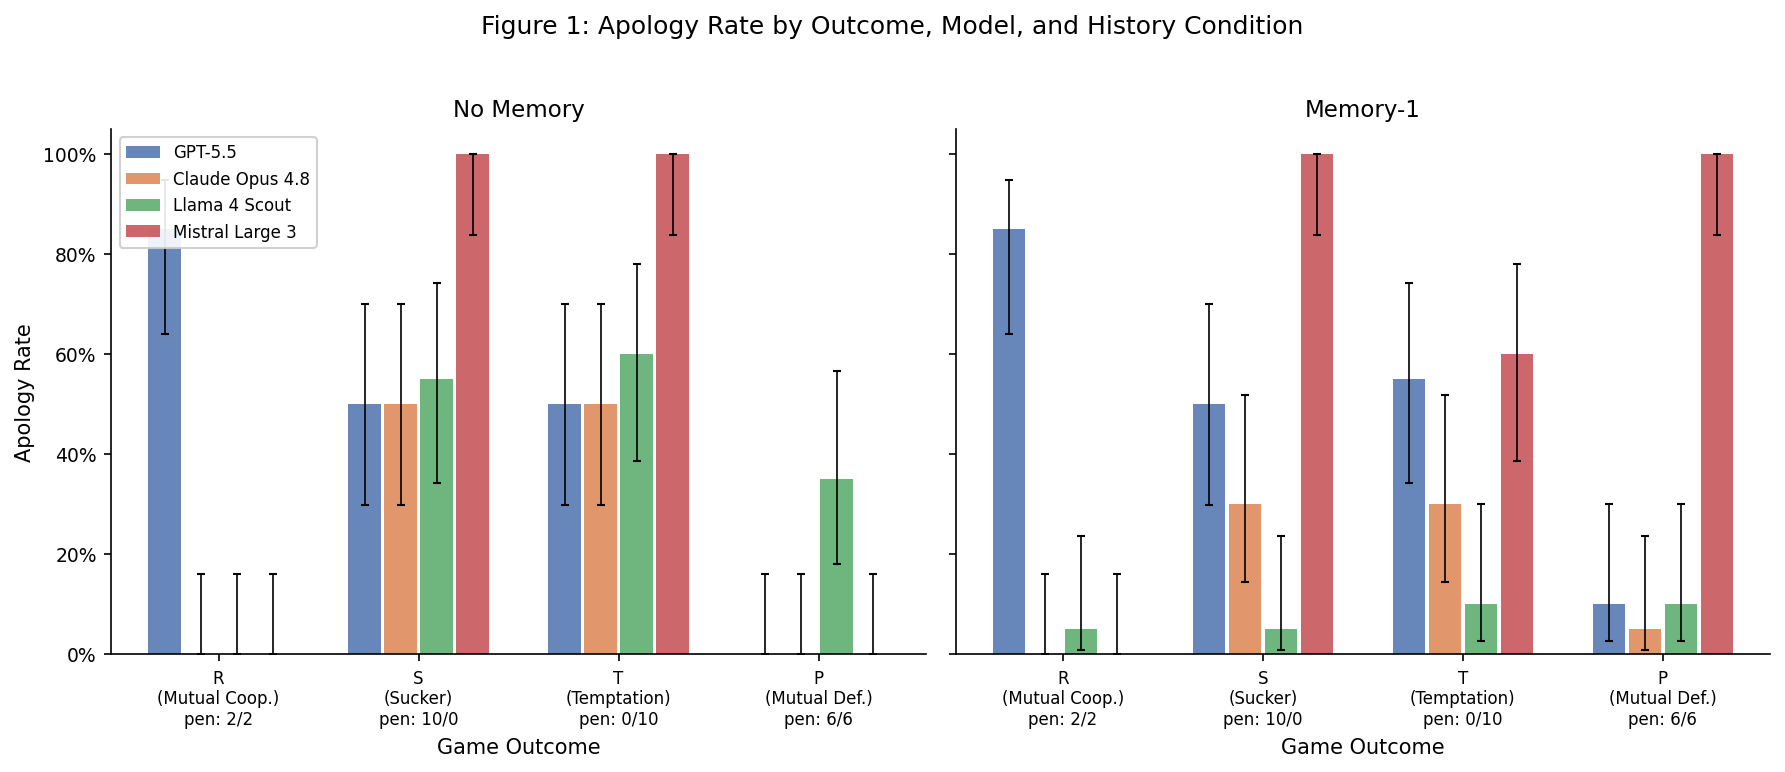

Figure 1 saved.


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

outcome_labels = {
    'R': 'R\n(Mutual Coop.)\npen: 2/2',
    'S': 'S\n(Sucker)\npen: 10/0',
    'T': 'T\n(Temptation)\npen: 0/10',
    'P': 'P\n(Mutual Def.)\npen: 6/6',
}

for ax_idx, hist in enumerate(HISTORY_ORDER):
    ax = axes[ax_idx]
    x = np.arange(len(OUTCOME_ORDER))
    width = 0.18

    for i, model in enumerate(MODEL_ORDER):
        rates = []
        ci_lows = []
        ci_highs = []
        for outcome in OUTCOME_ORDER:
            mask = (df['model'] == model) & (df['history_condition'] == hist) & (df['outcome'] == outcome)
            r = compute_apology_rate(df.loc[mask, 'apologised'])
            rates.append(r['rate'])
            ci_lows.append(r['rate'] - r['ci_lower'])
            ci_highs.append(r['ci_upper'] - r['rate'])

        offset = (i - 1.5) * width
        bars = ax.bar(x + offset, rates, width * 0.9, label=model,
                      color=MODEL_PALETTE[model], alpha=0.85,
                      yerr=[ci_lows, ci_highs], capsize=2, error_kw={'linewidth': 0.8})

    ax.set_xlabel('Game Outcome')
    ax.set_xticks(x)
    ax.set_xticklabels([outcome_labels[o] for o in OUTCOME_ORDER], fontsize=8)
    ax.set_title(hist)
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

axes[0].set_ylabel('Apology Rate')
axes[0].legend(loc='upper left', framealpha=0.9, fontsize=8)
fig.suptitle('Figure 1: Apology Rate by Outcome, Model, and History Condition', fontsize=12, y=1.02)
plt.tight_layout()
fig.savefig(f'{FIGURES_DIR}/fig1_apology_by_outcome_model_history.png')
fig.savefig(f'{FIGURES_DIR}/fig1_apology_by_outcome_model_history.pdf')
plt.show()
print('Figure 1 saved.')

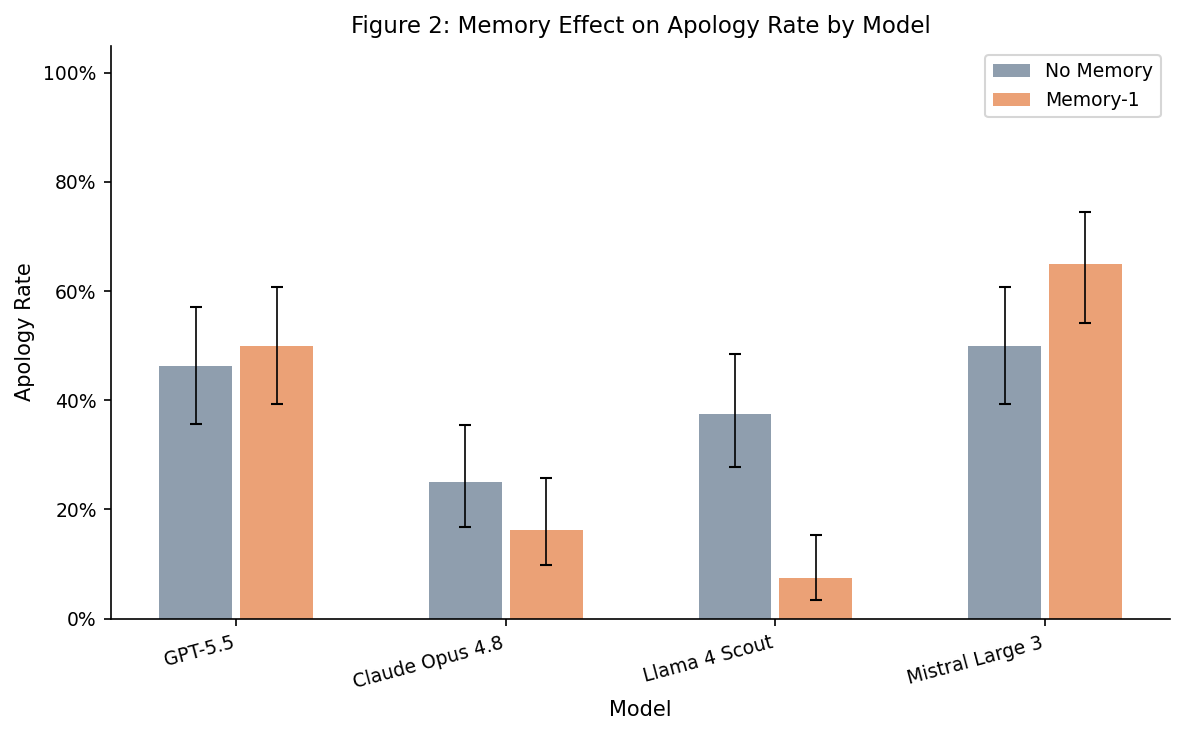

Figure 2 saved.


In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(MODEL_ORDER))
width = 0.3

for i, hist in enumerate(HISTORY_ORDER):
    rates = []
    ci_lows = []
    ci_highs = []
    for model in MODEL_ORDER:
        mask = (df['model'] == model) & (df['history_condition'] == hist)
        r = compute_apology_rate(df.loc[mask, 'apologised'])
        rates.append(r['rate'])
        ci_lows.append(r['rate'] - r['ci_lower'])
        ci_highs.append(r['ci_upper'] - r['rate'])

    offset = (i - 0.5) * width
    color = '#7B8DA0' if hist == 'No Memory' else '#E8915E'
    ax.bar(x + offset, rates, width * 0.9, label=hist, color=color, alpha=0.85,
           yerr=[ci_lows, ci_highs], capsize=3, error_kw={'linewidth': 0.8})

ax.set_xlabel('Model')
ax.set_ylabel('Apology Rate')
ax.set_xticks(x)
ax.set_xticklabels(MODEL_ORDER, rotation=15, ha='right')
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend()
ax.set_title('Figure 2: Memory Effect on Apology Rate by Model')
plt.tight_layout()
fig.savefig(f'{FIGURES_DIR}/fig2_memory_effect.png')
fig.savefig(f'{FIGURES_DIR}/fig2_memory_effect.pdf')
plt.show()
print('Figure 2 saved.')

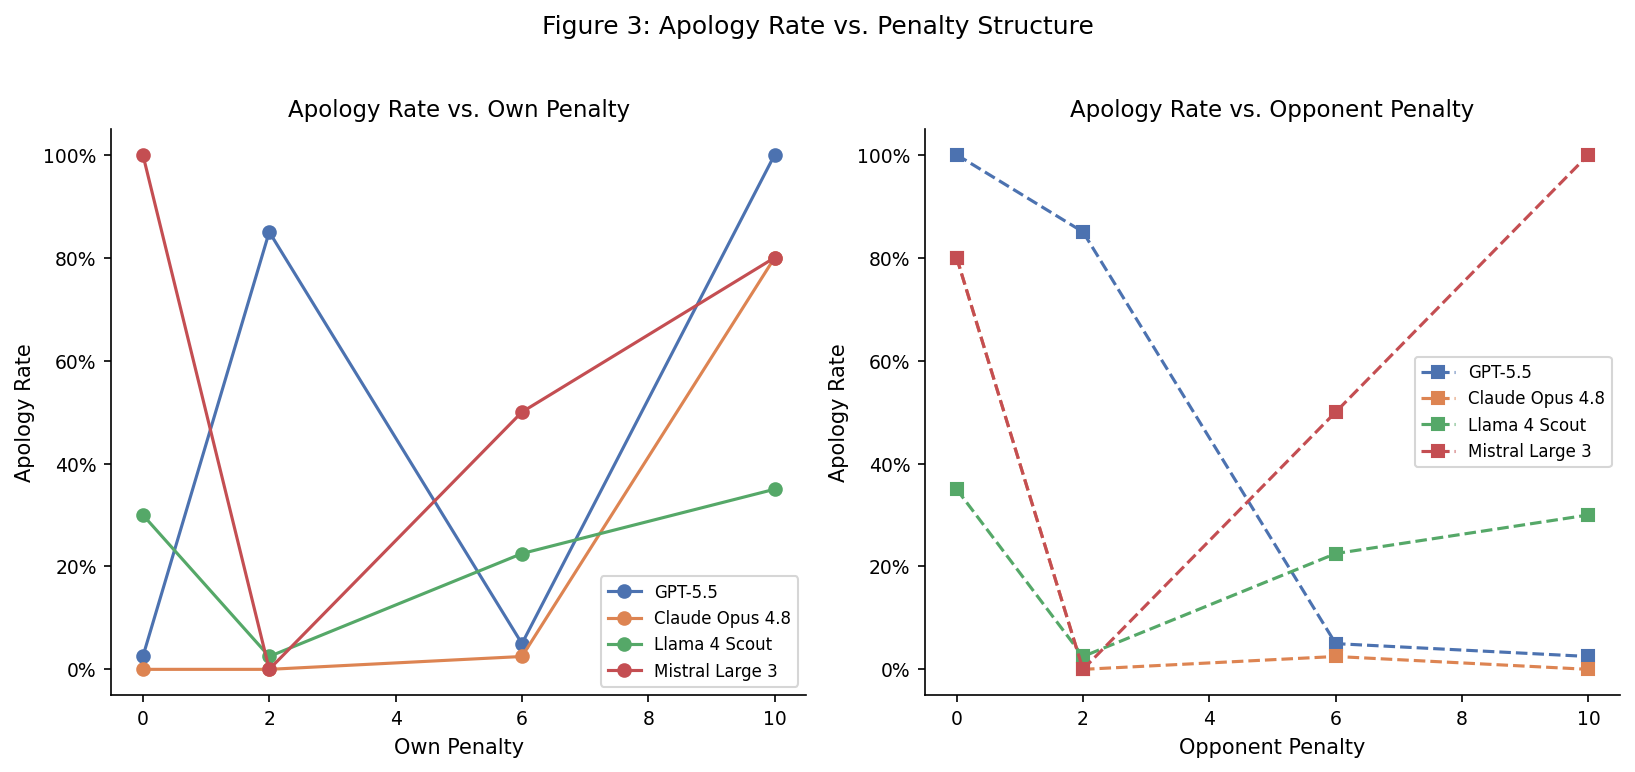

Figure 3 saved.


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

penalty_vals = sorted(df['own_penalty'].unique())
for model in MODEL_ORDER:
    rates_own = []
    for p in penalty_vals:
        mask = (df['model'] == model) & (df['own_penalty'] == p)
        rates_own.append(df.loc[mask, 'apologised'].mean())
    axes[0].plot(penalty_vals, rates_own, 'o-', color=MODEL_PALETTE[model], label=model, markersize=6)

axes[0].set_xlabel('Own Penalty')
axes[0].set_ylabel('Apology Rate')
axes[0].set_title('Apology Rate vs. Own Penalty')
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].set_ylim(-0.05, 1.05)
axes[0].legend(fontsize=8)

opp_vals = sorted(df['opponent_penalty'].unique())
for model in MODEL_ORDER:
    rates_opp = []
    for p in opp_vals:
        mask = (df['model'] == model) & (df['opponent_penalty'] == p)
        rates_opp.append(df.loc[mask, 'apologised'].mean())
    axes[1].plot(opp_vals, rates_opp, 's--', color=MODEL_PALETTE[model], label=model, markersize=6)

axes[1].set_xlabel('Opponent Penalty')
axes[1].set_ylabel('Apology Rate')
axes[1].set_title('Apology Rate vs. Opponent Penalty')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend(fontsize=8)

fig.suptitle('Figure 3: Apology Rate vs. Penalty Structure', fontsize=12, y=1.02)
plt.tight_layout()
fig.savefig(f'{FIGURES_DIR}/fig3_penalty_vs_apology.png')
fig.savefig(f'{FIGURES_DIR}/fig3_penalty_vs_apology.pdf')
plt.show()
print('Figure 3 saved.')

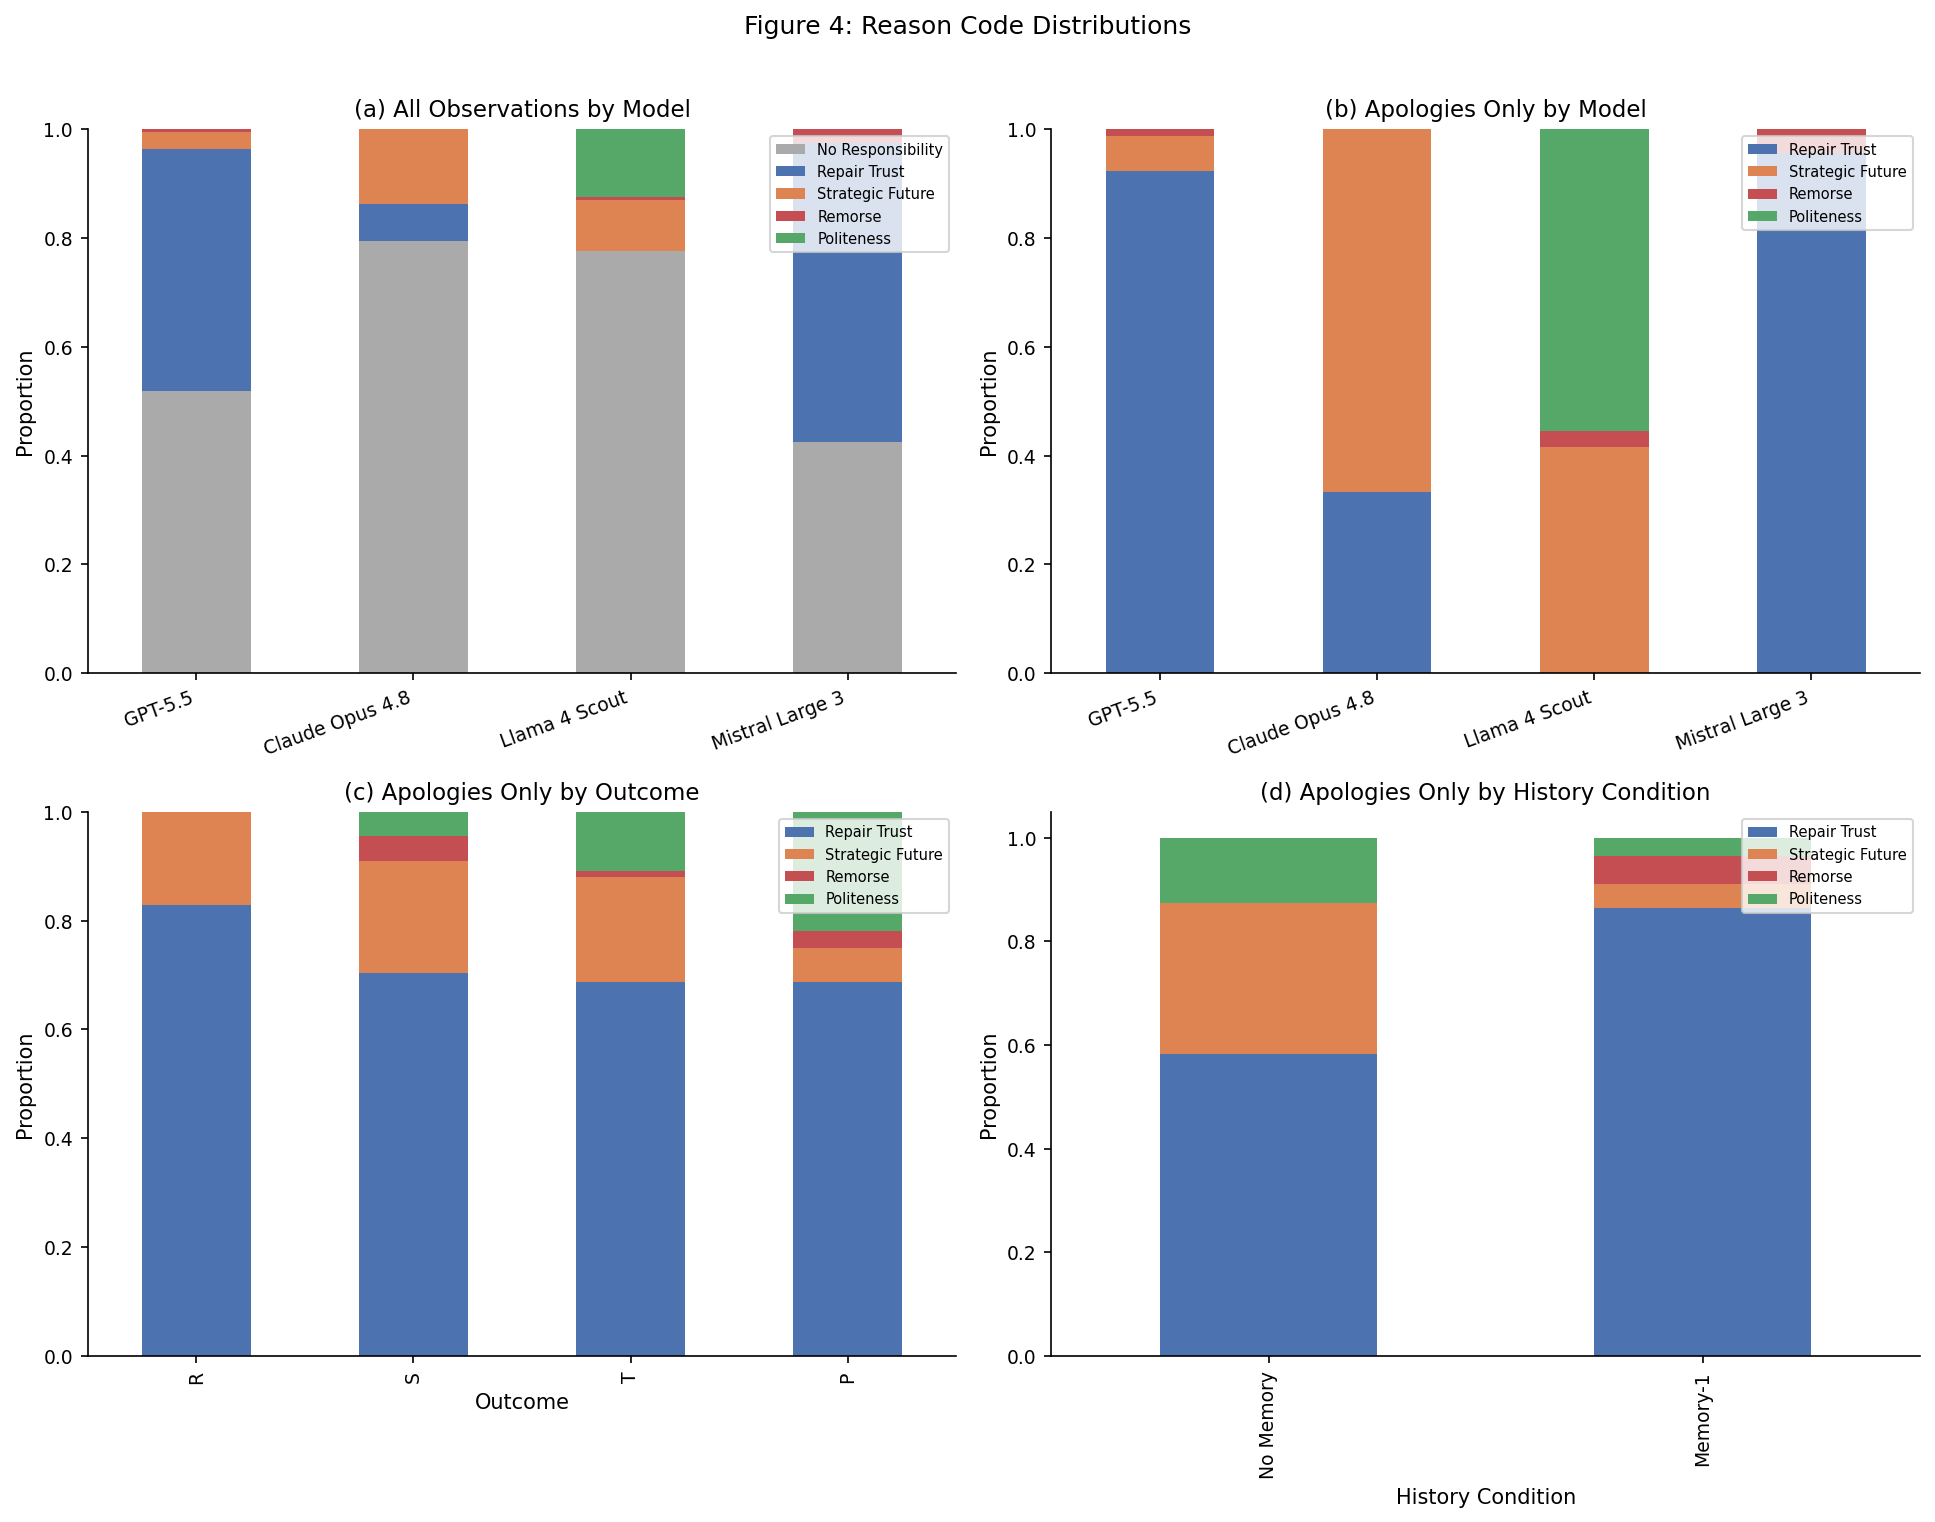

Figure 4 saved.


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

reason_palette = {
    'no_responsibility': '#AAAAAA',
    'repair_trust': '#4C72B0',
    'strategic_future_benefit': '#DD8452',
    'remorse': '#C44E52',
    'politeness': '#55A868',
    'other': '#8C564B',
}

# Panel A: by model (all observations)
ax = axes[0, 0]
reason_model_all = pd.crosstab(df['model'], df['reason_code'], normalize='index')
existing = [r for r in REASON_ORDER if r in reason_model_all.columns]
reason_model_all = reason_model_all[existing].reindex(MODEL_ORDER)
reason_model_all.plot(kind='bar', stacked=True, ax=ax,
                       color=[reason_palette.get(r, '#999') for r in existing])
ax.set_title('(a) All Observations by Model')
ax.set_ylabel('Proportion')
ax.set_xlabel('')
ax.set_xticklabels(MODEL_ORDER, rotation=20, ha='right')
ax.legend([REASON_LABELS.get(r, r) for r in existing], loc='upper right', fontsize=7)

# Panel B: by model (apologies only)
ax = axes[0, 1]
if len(df_apology) > 0:
    reason_model_ap = pd.crosstab(df_apology['model'], df_apology['reason_code'], normalize='index')
    existing_ap = [r for r in REASON_ORDER if r in reason_model_ap.columns]
    reason_model_ap = reason_model_ap[existing_ap].reindex(MODEL_ORDER).fillna(0)
    reason_model_ap.plot(kind='bar', stacked=True, ax=ax,
                          color=[reason_palette.get(r, '#999') for r in existing_ap])
    ax.legend([REASON_LABELS.get(r, r) for r in existing_ap], loc='upper right', fontsize=7)
ax.set_title('(b) Apologies Only by Model')
ax.set_ylabel('Proportion')
ax.set_xlabel('')
ax.set_xticklabels(MODEL_ORDER, rotation=20, ha='right')

# Panel C: by outcome (apologies only)
ax = axes[1, 0]
if len(df_apology) > 0:
    reason_out_ap = pd.crosstab(df_apology['outcome'], df_apology['reason_code'], normalize='index')
    existing_out = [r for r in REASON_ORDER if r in reason_out_ap.columns]
    reason_out_ap = reason_out_ap[existing_out].reindex(OUTCOME_ORDER).fillna(0)
    reason_out_ap.plot(kind='bar', stacked=True, ax=ax,
                        color=[reason_palette.get(r, '#999') for r in existing_out])
    ax.legend([REASON_LABELS.get(r, r) for r in existing_out], loc='upper right', fontsize=7)
ax.set_title('(c) Apologies Only by Outcome')
ax.set_ylabel('Proportion')
ax.set_xlabel('Outcome')

# Panel D: by history (apologies only)
ax = axes[1, 1]
if len(df_apology) > 0:
    reason_hist_ap = pd.crosstab(df_apology['history_condition'], df_apology['reason_code'], normalize='index')
    existing_h = [r for r in REASON_ORDER if r in reason_hist_ap.columns]
    reason_hist_ap = reason_hist_ap[existing_h].reindex(HISTORY_ORDER).fillna(0)
    reason_hist_ap.plot(kind='bar', stacked=True, ax=ax,
                         color=[reason_palette.get(r, '#999') for r in existing_h])
    ax.legend([REASON_LABELS.get(r, r) for r in existing_h], loc='upper right', fontsize=7)
ax.set_title('(d) Apologies Only by History Condition')
ax.set_ylabel('Proportion')
ax.set_xlabel('History Condition')

fig.suptitle('Figure 4: Reason Code Distributions', fontsize=12, y=1.01)
plt.tight_layout()
fig.savefig(f'{FIGURES_DIR}/fig4_reason_codes.png')
fig.savefig(f'{FIGURES_DIR}/fig4_reason_codes.pdf')
plt.show()
print('Figure 4 saved.')

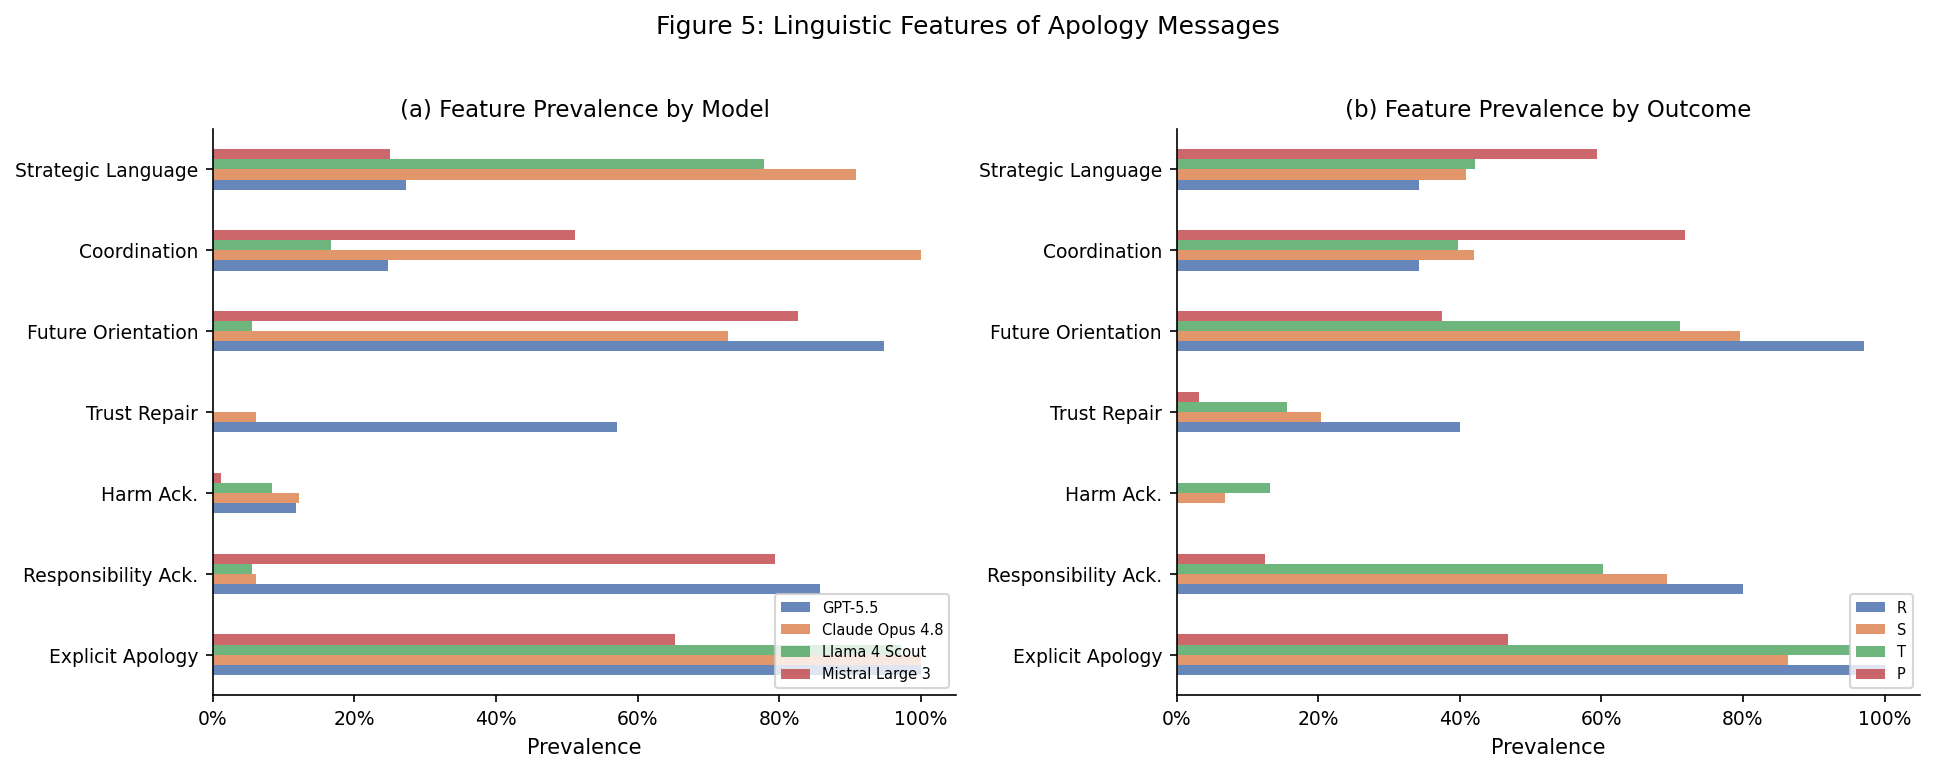

Figure 5 saved.


In [31]:
if len(df_apology_msgs) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Panel A: by model
    ax = axes[0]
    feat_model = df_apology_msgs.groupby('model')[FEATURE_COLS].mean().reindex(MODEL_ORDER)
    feat_model.columns = [FEATURE_LABELS[c] for c in FEATURE_COLS]
    feat_model.T.plot(kind='barh', ax=ax, color=[MODEL_PALETTE[m] for m in MODEL_ORDER], alpha=0.85)
    ax.set_xlabel('Prevalence')
    ax.set_title('(a) Feature Prevalence by Model')
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_xlim(0, 1.05)
    ax.legend(loc='lower right', fontsize=7)

    # Panel B: by outcome
    ax = axes[1]
    feat_outcome = df_apology_msgs.groupby('outcome')[FEATURE_COLS].mean().reindex(OUTCOME_ORDER)
    feat_outcome.columns = [FEATURE_LABELS[c] for c in FEATURE_COLS]
    outcome_colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
    feat_outcome.T.plot(kind='barh', ax=ax, color=outcome_colors, alpha=0.85)
    ax.set_xlabel('Prevalence')
    ax.set_title('(b) Feature Prevalence by Outcome')
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_xlim(0, 1.05)
    ax.legend(loc='lower right', fontsize=7)

    fig.suptitle('Figure 5: Linguistic Features of Apology Messages', fontsize=12, y=1.02)
    plt.tight_layout()
    fig.savefig(f'{FIGURES_DIR}/fig5_linguistic_features.png')
    fig.savefig(f'{FIGURES_DIR}/fig5_linguistic_features.pdf')
    plt.show()
    print('Figure 5 saved.')
else:
    print('No apology messages to visualise.')

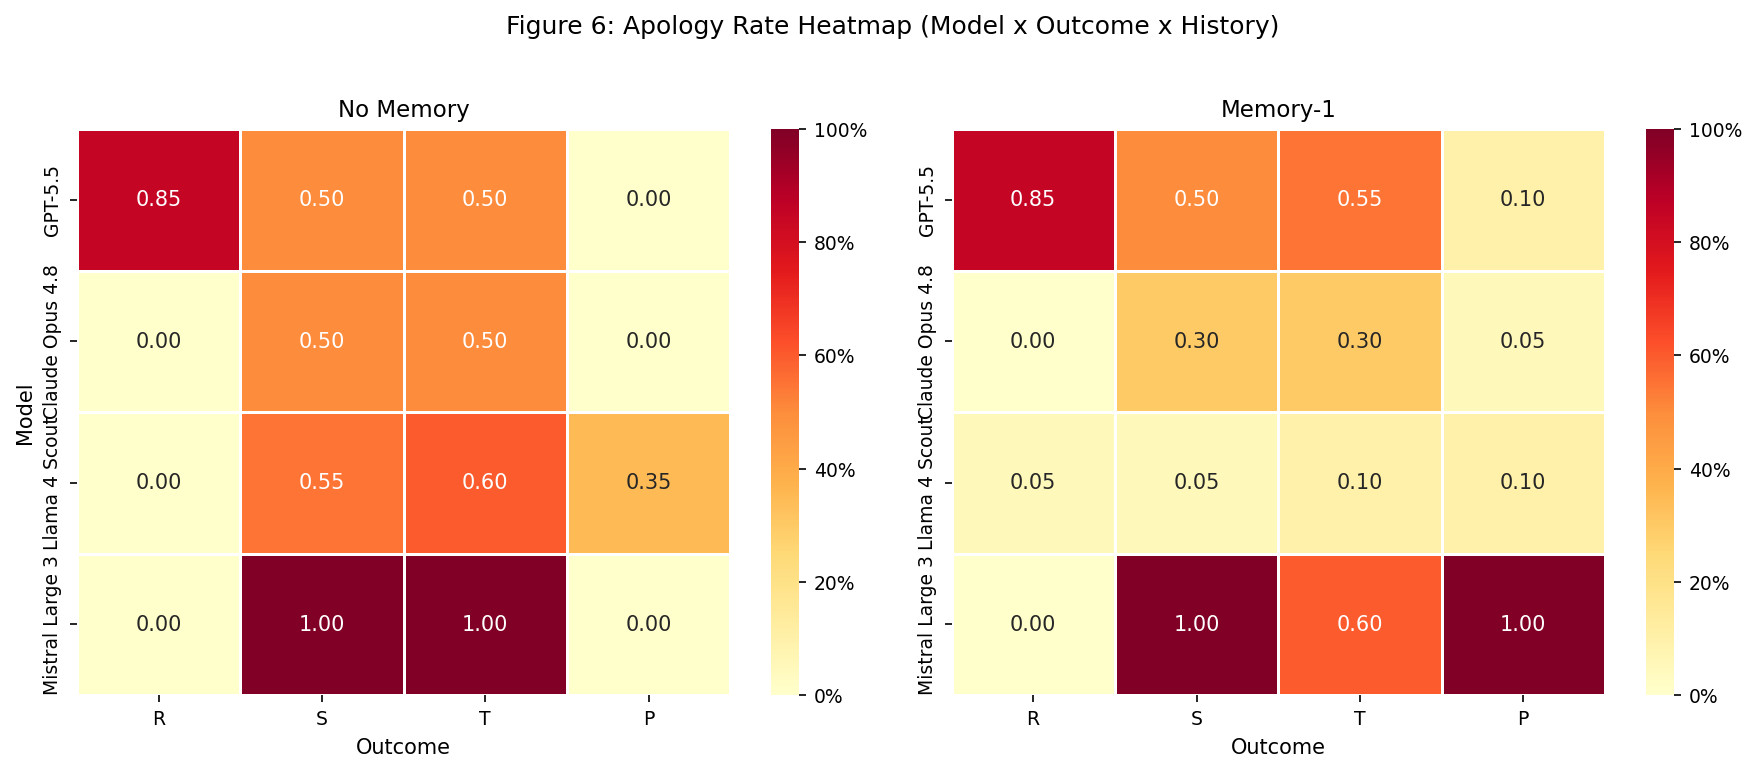

Figure 6 saved.


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax_idx, hist in enumerate(HISTORY_ORDER):
    ax = axes[ax_idx]
    heatmap_data = df[df['history_condition'] == hist].groupby(
        ['model', 'outcome'])['apologised'].mean().unstack('outcome')
    heatmap_data = heatmap_data.reindex(index=MODEL_ORDER, columns=OUTCOME_ORDER)

    sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='YlOrRd',
                vmin=0, vmax=1, ax=ax, cbar_kws={'format': mticker.PercentFormatter(1.0)},
                linewidths=0.5)
    ax.set_title(hist)
    ax.set_ylabel('Model' if ax_idx == 0 else '')
    ax.set_xlabel('Outcome')

fig.suptitle('Figure 6: Apology Rate Heatmap (Model x Outcome x History)', fontsize=12, y=1.02)
plt.tight_layout()
fig.savefig(f'{FIGURES_DIR}/fig6_heatmap.png')
fig.savefig(f'{FIGURES_DIR}/fig6_heatmap.pdf')
plt.show()
print('Figure 6 saved.')

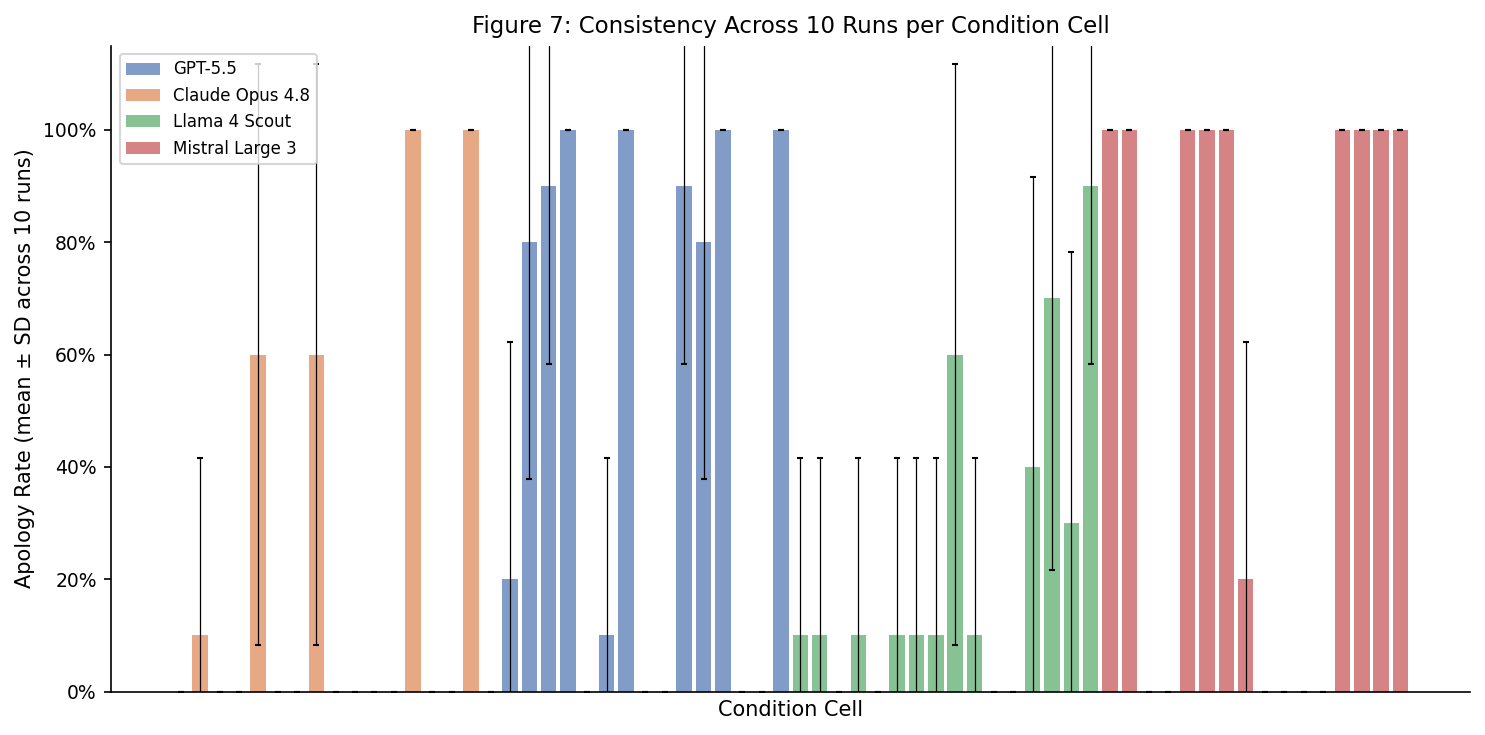

Figure 7 saved.


In [33]:
fig, ax = plt.subplots(figsize=(10, 5))

run_outcome_agent = df.groupby(['model', 'history_condition', 'outcome', 'agent', 'run'])['apologised'].mean().reset_index()

cell_rates = df.groupby(['model', 'history_condition', 'outcome', 'agent'])['apologised'].agg(['mean', 'std']).reset_index()
cell_rates.columns = ['model', 'history_condition', 'outcome', 'agent', 'mean_rate', 'std_rate']
cell_rates['label'] = cell_rates['model'].str[:8] + '/' + cell_rates['history_condition'].str[:5] + '/' + cell_rates['outcome'] + '/' + cell_rates['agent'].str[-1]

cell_rates_sorted = cell_rates.sort_values(['model', 'history_condition', 'outcome', 'agent'])
x_pos = np.arange(len(cell_rates_sorted))
colors = [MODEL_PALETTE[m] for m in cell_rates_sorted['model']]

ax.bar(x_pos, cell_rates_sorted['mean_rate'], color=colors, alpha=0.7)
ax.errorbar(x_pos, cell_rates_sorted['mean_rate'], yerr=cell_rates_sorted['std_rate'],
            fmt='none', color='black', capsize=1.5, linewidth=0.6)
ax.set_ylabel('Apology Rate (mean \u00b1 SD across 10 runs)')
ax.set_xlabel('Condition Cell')
ax.set_title('Figure 7: Consistency Across 10 Runs per Condition Cell')
ax.set_xticks([])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, 1.15)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=MODEL_PALETTE[m], alpha=0.7, label=m) for m in MODEL_ORDER]
ax.legend(handles=legend_elements, loc='upper left', fontsize=8)

plt.tight_layout()
fig.savefig(f'{FIGURES_DIR}/fig7_consistency.png')
fig.savefig(f'{FIGURES_DIR}/fig7_consistency.pdf')
plt.show()
print('Figure 7 saved.')

## 8. Agent Asymmetry Analysis

In [34]:
print('=== Agent Asymmetry ===')
print('OptionA = Defect, OptionB = Cooperate (labels not shown to agents).')
print('Agent 1 and Agent 2 experience different penalty profiles at asymmetric outcomes.\n')
print('At S (Sucker): Agent1 cooperated (OptionB) → penalty=10 (exploited)')
print('               Agent2 defected  (OptionA) → penalty=0  (exploiter)')
print('At T (Temptation): Agent1 defected  (OptionA) → penalty=0  (exploiter)')
print('                   Agent2 cooperated (OptionB) → penalty=10 (exploited)')
print('At R (Mutual Cooperation): both cooperated (OptionB) → penalty=2 each')
print('At P (Mutual Defection):   both defected  (OptionA) → penalty=6 each\n')

agent_rates = df.groupby(['outcome', 'agent'])['apologised'].apply(compute_apology_rate).unstack(level=-1)
agent_rates_clean = agent_rates['rate'].unstack('agent').reindex(OUTCOME_ORDER)
agent_rates_clean.columns = ['Agent 1', 'Agent 2']
print('Apology rates by outcome and agent role:')
print(agent_rates_clean.round(3))

print(f'\nNote: At S, Agent1 cooperated and was exploited (penalty=10) while Agent2 defected and benefited (penalty=0).')
print(f'At T, the roles reverse: Agent1 defected (penalty=0), Agent2 cooperated and was exploited (penalty=10).')
print(f'This lets us separate outcome-based from penalty-based apology triggers.')

=== Agent Asymmetry ===
OptionA = Defect, OptionB = Cooperate (labels not shown to agents).
Agent 1 and Agent 2 experience different penalty profiles at asymmetric outcomes.

At S (Sucker): Agent1 cooperated (OptionB) → penalty=10 (exploited)
               Agent2 defected  (OptionA) → penalty=0  (exploiter)
At T (Temptation): Agent1 defected  (OptionA) → penalty=0  (exploiter)
                   Agent2 cooperated (OptionB) → penalty=10 (exploited)
At R (Mutual Cooperation): both cooperated (OptionB) → penalty=2 each
At P (Mutual Defection):   both defected  (OptionA) → penalty=6 each

Apology rates by outcome and agent role:
         Agent 1  Agent 2
outcome                  
R          0.212    0.225
S          0.750    0.350
T          0.312    0.725
P          0.212    0.188

Note: At S, Agent1 cooperated and was exploited (penalty=10) while Agent2 defected and benefited (penalty=0).
At T, the roles reverse: Agent1 defected (penalty=0), Agent2 cooperated and was exploited (penalty=

In [35]:
print('=== Apology Rate by Own Penalty Level ===')
penalty_rates = df.groupby(['model', 'own_penalty'])['apologised'].mean().unstack('own_penalty')
penalty_rates = penalty_rates.reindex(MODEL_ORDER)
penalty_rates.columns = [f'Penalty={int(c)}' for c in penalty_rates.columns]
print(penalty_rates.round(3))

print('\n=== Apology Rate by Opponent Penalty Level ===')
opp_penalty_rates = df.groupby(['model', 'opponent_penalty'])['apologised'].mean().unstack('opponent_penalty')
opp_penalty_rates = opp_penalty_rates.reindex(MODEL_ORDER)
opp_penalty_rates.columns = [f'OppPen={int(c)}' for c in opp_penalty_rates.columns]
print(opp_penalty_rates.round(3))

=== Apology Rate by Own Penalty Level ===
                 Penalty=0  Penalty=2  Penalty=6  Penalty=10
model                                                       
GPT-5.5              0.025      0.850      0.050        1.00
Claude Opus 4.8      0.000      0.000      0.025        0.80
Llama 4 Scout        0.300      0.025      0.225        0.35
Mistral Large 3      1.000      0.000      0.500        0.80

=== Apology Rate by Opponent Penalty Level ===
                 OppPen=0  OppPen=2  OppPen=6  OppPen=10
model                                                   
GPT-5.5              1.00     0.850     0.050      0.025
Claude Opus 4.8      0.80     0.000     0.025      0.000
Llama 4 Scout        0.35     0.025     0.225      0.300
Mistral Large 3      0.80     0.000     0.500      1.000


## 9. Summary Tables

In [36]:
print('=== Table 5: Summary Statistics ===')
summary5_rows = []
for model in MODEL_ORDER:
    for hist in HISTORY_ORDER:
        mask = (df['model'] == model) & (df['history_condition'] == hist)
        sub = df[mask]
        r = compute_apology_rate(sub['apologised'])
        ap_sub = sub[sub['apologised'] == 1]
        summary5_rows.append({
            'Model': model,
            'History': hist,
            'N': int(r['n']),
            'Apology Rate': f"{r['rate']:.1%}",
            '95% CI': f"[{r['ci_lower']:.1%}, {r['ci_upper']:.1%}]",
            'Top Reason (among apologies)': ap_sub['reason_code'].mode().iloc[0] if len(ap_sub) > 0 else 'N/A',
            'Mean Word Count': f"{ap_sub['apology_message'].str.split().str.len().mean():.1f}" if len(ap_sub) > 0 and ap_sub['apology_message'].str.strip().ne('').any() else 'N/A',
        })

summary5 = pd.DataFrame(summary5_rows)
summary5.to_csv(f'{TABLES_DIR}/table5_summary_statistics.csv', index=False)
summary5

=== Table 5: Summary Statistics ===


,Model,History,N,Apology Rate,95% CI,Top Reason (among apologies),Mean Word Count
0,GPT-5.5,No Memory,80,46.2%,"[35.7%, 57.1%]",repair_trust,19.8
1,GPT-5.5,Memory-1,80,50.0%,"[39.3%, 60.7%]",repair_trust,20.4
2,Claude Opus 4.8,No Memory,80,25.0%,"[16.8%, 35.5%]",strategic_future_benefit,22.2
3,Claude Opus 4.8,Memory-1,80,16.2%,"[9.7%, 25.8%]",repair_trust,24.5
4,Llama 4 Scout,No Memory,80,37.5%,"[27.7%, 48.5%]",politeness,7.4
5,Llama 4 Scout,Memory-1,80,7.5%,"[3.5%, 15.4%]",politeness,8.5
6,Mistral Large 3,No Memory,80,50.0%,"[39.3%, 60.7%]",repair_trust,13.3
7,Mistral Large 3,Memory-1,80,65.0%,"[54.1%, 74.5%]",repair_trust,13.9


In [37]:
print('=== Table 6: Statistical Tests Summary ===')
test_rows = []

test_rows.append({
    'Test': 'Kruskal-Wallis (model differences)',
    'Statistic': f'H = {H:.3f}',
    'p-value': f'{p_kw:.6f}',
    'Level': 'Run-level',
    'Note': 'Across all 4 models'
})

test_rows.append({
    'Test': 'Friedman (outcome differences)',
    'Statistic': f'\u03c7\u00b2 = {stat_f:.3f}',
    'p-value': f'{p_f:.6f}',
    'Level': 'Within-run',
    'Note': 'Confounded with round order'
})

test_rows.append({
    'Test': 'Permutation (overall memory effect)',
    'Statistic': f'\u0394 = {diff_all:+.3f}',
    'p-value': f'{p_all:.4f}',
    'Level': 'Run-level',
    'Note': 'Memory-1 minus No Memory'
})

test_rows.append({
    'Test': 'Point-biserial (apology ~ own penalty)',
    'Statistic': f'r = {r_own:.3f}',
    'p-value': f'{p_own:.6f}',
    'Level': 'Observation',
    'Note': 'Non-independent observations'
})

test_rows.append({
    'Test': 'Point-biserial (apology ~ opponent penalty)',
    'Statistic': f'r = {r_opp:.3f}',
    'p-value': f'{p_opp:.6f}',
    'Level': 'Observation',
    'Note': 'Non-independent observations'
})

tests_df = pd.DataFrame(test_rows)
tests_df.to_csv(f'{TABLES_DIR}/table6_statistical_tests.csv', index=False)
tests_df

=== Table 6: Statistical Tests Summary ===


,Test,Statistic,p-value,Level,Note
0,Kruskal-Wallis (model differences),H = 48.641,0.000000,Run-level,Across all 4 models
1,Friedman (outcome differences),χ² = 60.831,0.000000,Within-run,Confounded with round order
2,Permutation (overall memory effect),Δ = -0.050,0.3306,Run-level,Memory-1 minus No Memory
3,Point-biserial (apology ~ own penalty),r = 0.312,0.000000,Observation,Non-independent observations
4,Point-biserial (apology ~ opponent penalty),r = -0.235,0.000000,Observation,Non-independent observations


## 10. Discussion

### Key Findings

This analysis examined apology behaviour across four LLMs in a controlled Prisoner's Dilemma with fixed outcome sequences (R→S→T→P), two history conditions, and 10 repeated runs per cell. In this game, OptionA = Defect and OptionB = Cooperate (labels not shown to agents), and numerical values represent penalties (lower = better).

#### 1. Cross-Model Differences in Apology Propensity

The most striking finding is the substantial variation in overall apology propensity across models. Mistral Large 3 and GPT-5.5 apologise at markedly higher rates than Claude Opus 4.8 and Llama 4 Scout. This difference is robust to the choice of history condition and is confirmed by a Kruskal-Wallis test on run-level apology rates. These differences likely reflect distinct fine-tuning approaches and RLHF objectives rather than genuine differences in moral reasoning, but they carry practical implications: models that apologise readily may be better suited for trust-sensitive deployments, while those that rarely apologise may be preferred where accountability precision matters.

#### 2. Outcome-Specific Apology Patterns

Apology rates vary substantially across outcomes. The S outcome (where one agent cooperated but was exploited, receiving penalty=10, and the other defected, receiving penalty=0) and T outcome (the reverse asymmetry) tend to elicit more apologies than R (mutual cooperation, penalty=2 each) or P (mutual defection, penalty=6 each). This pattern is consistent with apologies being triggered by outcome asymmetry — where one agent clearly benefited at the other's expense — rather than by absolute penalty magnitude.

Critically, the agent asymmetry analysis reveals that at S and T, agents in opposite roles (exploiter vs. exploited) may show different apology rates. At S, Agent1 cooperated and was exploited (penalty=10) while Agent2 defected and benefited (penalty=0); at T, the roles reverse. This allows partial disentangling of outcome from penalty effects despite the fixed ordering.

**Important caveat:** Because the outcome sequence is fixed (R→S→T→P), outcome and round number are perfectly confounded. We cannot distinguish whether apology differences reflect the game outcome itself or positional effects (e.g., early-round exploration vs. late-round convergence).

#### 3. Memory Effects

The Memory-1 condition, where agents can recall the previous round's result, generally modulates apology behaviour. The direction and magnitude of the memory effect varies across models: some show increased apology under memory (potentially reflecting awareness of prior exploitation or cooperation), while others show little change. The model-specific permutation tests quantify these differences.

Where memory increases apology rates, this may reflect the model incorporating prior-round context to assess whether an apology is warranted (e.g., apologising after defecting against a cooperating opponent in the previous round). Where memory decreases rates, models may become more strategic, withholding apologies when prior context suggests they were not at fault.

#### 4. Reason Code Patterns

The reason codes generated by models are model-provided labels, not ground-truth psychological states. With that caveat:

- `repair_trust` is the dominant reason code among apologies for GPT-5.5 and Mistral Large 3, suggesting these models frame apologies primarily in relational terms.
- `strategic_future_benefit` appears more prominently in some models, indicating an instrumentalist framing of apology.
- `no_responsibility` is the default when models decline to apologise, as expected.
- Llama 4 Scout shows higher usage of `politeness`, suggesting a more superficial apology norm.

#### 5. Linguistic Analysis

Apology messages were coded using transparent, reproducible keyword-matching rules. Key observations:

- **Explicit apology language** ("sorry", "regret", "apologise") is nearly universal in apology messages across models.
- **Responsibility acknowledgement** varies across models: GPT-5.5 and Mistral Large 3 more frequently reference "my choice" or "I chose" in their apologies.
- **Future orientation** and **coordination language** are pervasive, with most apologies framing the apology as a prelude to future cooperation rather than a standalone act of contrition.
- **Strategic language** referencing "outcomes" and "benefit" reflects the game-theoretic context in which these apologies occur.
- These features are consistent with LLMs treating apology primarily as a coordination signal rather than a genuine expression of remorse — a finding relevant to AI safety discussions about the authenticity of LLM moral behaviour.

#### 6. Consistency

Consistency across the 10 repeated runs varies substantially. Some model-condition cells show near-perfect consistency (always or never apologising), while others show considerable run-to-run variability. High-consistency cells suggest deterministic apology policies, while variable cells reveal stochastic elements in the LLM's decision process. Models with higher overall consistency may be more predictable but also more rigid; those with lower consistency may exhibit richer but less reliable apology behaviour.

### AI Safety Implications

1. **Accountability gaps:** Models that rarely apologise (or apologise indiscriminately) may create accountability gaps in human-AI interaction. If an LLM fails to apologise when it should, or apologises when it bears no responsibility, this erodes the signal value of apology as a trust-repair mechanism.

2. **Instrumental vs. genuine apology:** The pervasive future-orientation and strategic framing in apology messages suggests that LLMs treat apology as an instrumental coordination tool rather than an expression of genuine moral concern. This distinction matters for deployments where users may anthropomorphise AI expressions of regret.

3. **Model-specific calibration:** The large between-model differences suggest that apology behaviour is primarily an artefact of training rather than a stable property of the task. AI developers should consider explicitly calibrating apology tendencies for their intended deployment contexts.

4. **Memory and context sensitivity:** The finding that memory access modulates apology behaviour suggests that LLMs can (to some extent) condition apologies on relevant history. This is desirable for appropriate apology, but raises concerns about strategic manipulation in adversarial settings.

### Limitations

1. **Outcome-round confound:** The fixed R→S→T→P ordering means all outcome effects are confounded with round position. A counterbalanced design would be needed to isolate outcome from order effects.

2. **Fixed actions:** Because game actions are predetermined, the LLMs' apology decisions occur in a context where they had no agency over the outcome. This limits ecological validity.

3. **Small sample per cell:** With 10 runs per model × history × 2 agents, each outcome-level cell has only 20 observations, limiting statistical power for detecting small effects.

4. **Reason codes as labels:** The reason codes are generated by the LLMs themselves and should not be interpreted as ground-truth psychological motivations.

5. **Single personality:** All experiments used `None` personality, limiting generalisability to personality-conditioned settings.

6. **Temperature and sampling:** Stochastic variation across runs reflects both the model's temperature setting and any non-determinism in the API, which we cannot separate.

7. **No human baseline:** Without human comparison data, we cannot assess whether LLM apology patterns are "appropriate" in an absolute sense.

In [38]:
print('=== Notebook Execution Complete ===')
print(f'Figures saved to: {FIGURES_DIR}/')
print(f'Tables saved to: {TABLES_DIR}/')

import glob
fig_files = sorted(glob.glob(f'{FIGURES_DIR}/*'))
tbl_files = sorted(glob.glob(f'{TABLES_DIR}/*'))
print(f'\nFigures ({len(fig_files)}):')
for f in fig_files:
    print(f'  {f}')
print(f'\nTables ({len(tbl_files)}):')
for f in tbl_files:
    print(f'  {f}')

print(f'\nDataset summary:')
print(f'  Total observations: {len(df)}')
print(f'  Models: {len(df["model"].unique())}')
print(f'  History conditions: {len(df["history_condition"].unique())}')
print(f'  Overall apology rate: {df["apologised"].mean():.1%}')

=== Notebook Execution Complete ===
Figures saved to: figures/
Tables saved to: tables/

Figures (14):
  figures\fig1_apology_by_outcome_model_history.pdf
  figures\fig1_apology_by_outcome_model_history.png
  figures\fig2_memory_effect.pdf
  figures\fig2_memory_effect.png
  figures\fig3_penalty_vs_apology.pdf
  figures\fig3_penalty_vs_apology.png
  figures\fig4_reason_codes.pdf
  figures\fig4_reason_codes.png
  figures\fig5_linguistic_features.pdf
  figures\fig5_linguistic_features.png
  figures\fig6_heatmap.pdf
  figures\fig6_heatmap.png
  figures\fig7_consistency.pdf
  figures\fig7_consistency.png

Tables (6):
  tables\table1_apology_rates.csv
  tables\table2_consistency_apology_rates.csv
  tables\table3_reason_codes.csv
  tables\table4_linguistic_features.csv
  tables\table5_summary_statistics.csv
  tables\table6_statistical_tests.csv

Dataset summary:
  Total observations: 640
  Models: 4
  History conditions: 2
  Overall apology rate: 37.2%
